# ☕ Coffee Leaf Disease Detection — Complete Pipeline (one notebook)

**Internship project · Debre Berhan University · College of Computing · Department of Data Science**

One notebook, run top to bottom, that covers every phase of the project (dataset statistics → EDA → image-quality analysis → cleaning → split → preprocessing → augmentation → baseline CNN → multi-architecture transfer learning → evaluation (metrics, confusion matrix, ROC/PR) → error analysis → model comparison → final model selection → saving → TFLite export for the Flutter app).

**Before you start:** `Runtime → Change runtime type → T4 GPU`. All settings are in the **configuration cell** (Part 1) — change values only there.

**Report mapping (Chapter Four of the guideline):**

| Notebook part | Phase (as given to you) | Report location |
|---|---|---|
| 2–4 | Data acquisition | Methodology → Resources/data |
| 5 | 4.1 Dataset statistics | Methodology → Data understanding |
| 6 | 4.2 Class distribution | Results |
| 7 | 4.3 Image visualization | Figures |
| 8 | 4.4 Dimension analysis | Results |
| 9 | 4.5 Image quality analysis | Methodology → Data quality |
| 10 | Phase 5 Data cleaning | Methodology → Data preparation |
| 11 | Phase 6 Train/val/test split | Methodology → Data preparation |
| 12 | Phase 7 Preprocessing | Methodology → Design |
| 13 | Phase 8 Augmentation | Methodology → Design |
| 14 | Phase 9 Baseline CNN | Methodology → Experimentation |
| 15 | Phase 10–13 Transfer learning (multi-architecture, two-stage, class imbalance) | Methodology → Implementation |
| 16 | Phase 14–16 Training config, callbacks, overfitting check | Methodology → Implementation |
| 17 | Phase 17–18 Metrics + confusion matrix | Results and Discussion |
| 18 | Phase 19 ROC / Precision-Recall | Results and Discussion |
| 19 | Phase 20 Error analysis | Results and Discussion; Limitations |
| 20 | Phase 22 Model comparison table | Results and Discussion |
| 21 | Phase 23 Final model selection | Results and Discussion; Conclusion |
| 22 | Phase 24 Save model + metadata | Methodology → Deployment |
| 23 | Real phone photos (optional) | Results and Discussion; Limitations |
| 24 | TFLite export for the app | Methodology → Deployment |
| 25 | Evidence pack | Figures/Tables, Appendices |

Every number and figure is produced by running the notebook — nothing is typed in by hand.

## 1. Configuration (edit only here)

In [1]:
# ================================ GENERAL ================================
SEED = 42
IMG_SIZE = (224, 224)          # used for every architecture (all support this with include_top=False)
BATCH_SIZE = 32

SOURCE = "kaggle"              # "kaggle" | "drive" | "zip"
DRIVE_DIR = "/content/drive/MyDrive/JMuBEN"

# ================================ SPLIT ================================
SPLIT_RATIOS = {"train": 0.70, "validation": 0.15, "test": 0.15}   # must sum to 1.0

# ================================ IMAGE QUALITY THRESHOLDS ================================
# These are starting points (rules of thumb), not an official standard — state that in the report,
# and justify any threshold you change by looking at the flagged images yourself.
DARK_MEAN_THRESHOLD = 30        # mean pixel intensity (0-255) below this -> "extremely dark"
BRIGHT_MEAN_THRESHOLD = 225     # mean pixel intensity above this -> "extremely bright"
BLUR_VARIANCE_THRESHOLD = 60    # Laplacian variance below this -> "blurred" (lower = blurrier)
GREEN_PIXEL_MIN_FRACTION = 0.05 # below this share of green/brown "leaf-like" pixels -> "possibly no leaf"
OUTLIER_PERCENTILE = 99         # per-class color-histogram distance above this percentile -> "review: possible mislabel"

# What Phase 5 (cleaning) actually REMOVES automatically vs only FLAGS for manual review.
# The guideline explicitly warns: do not remove images simply because they look different.
# Only "corrupt" and "exact_duplicate" (identical file content, MD5) are safe/objective enough to auto-remove.
# "near_duplicate_group" (perceptual hash) is a HEURISTIC: on a dataset of visually similar close-up leaf
# photos it can over-match and flag too much, so it is reviewed manually (next cells) before you decide to
# turn it on. It is always used for the leak-resistant SPLIT in Phase 6 regardless of this setting, with an
# automatic safety check there that disables it if it looks like it is over-collapsing the data.
AUTO_REMOVE = {"corrupt": True, "exact_duplicate": True, "near_duplicate_group": False,
              "blurred": False, "extreme_dark": False, "extreme_bright": False,
              "possibly_no_leaf": False, "possible_mislabel": False}
MANUAL_REVIEW_SAMPLE_SIZE = 24   # how many flagged images to actually LOOK AT before deciding

# ================================ TRAINING ================================
RUN_BASELINE = True
BASELINE_EPOCHS = 10
PHASE1_EPOCHS = 8               # transfer learning: train the new head (backbone frozen)
PHASE2_EPOCHS = 8               # transfer learning: fine-tune the last N layers
FINE_TUNE_LAST_N_LAYERS = 40

# Pick which pretrained backbones to actually train in this run.
# All five from the phase list are CONFIGURED below (Part 15) — add/remove names here.
# Training all five takes a long time on Colab; start with two, add more if you have time/quota.
ARCHITECTURES_TO_TRAIN = ["MobileNetV2", "EfficientNetB0"]   # also available: "ResNet50", "DenseNet121", "Xception"

CONF_THRESHOLD = 0.7            # "not sure" threshold suggested to the mobile app
RUN_REAL_PHOTO_TEST = False
DOWNLOAD_AT_END = True

# Class-balance verdict thresholds (rules of thumb, not an official standard)
BALANCED_MAX = 1.5
MODERATE_MAX = 4.0
# ===========================================================================
assert abs(sum(SPLIT_RATIOS.values()) - 1.0) < 1e-6, "SPLIT_RATIOS must sum to 1.0"

## 2. Setup

In [2]:
import os, re, sys, json, time, random, shutil, zipfile, hashlib, platform, subprocess
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                             precision_recall_curve, average_precision_score, roc_auc_score)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
try:
    import cv2
except ImportError:
    cv2 = None
    print("NOTE: opencv-python (cv2) not found -> blur detection will use a NumPy fallback.")

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
pd.set_option("display.width", 140)
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp")

EVIDENCE_DIR = "report_evidence"
os.makedirs(f"{EVIDENCE_DIR}/figures", exist_ok=True)
os.makedirs(f"{EVIDENCE_DIR}/tables", exist_ok=True)
RESULTS = {}

def save_fig(name):
    path = f"{EVIDENCE_DIR}/figures/{name}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print(f"[saved figure] {path}")

def save_table(frame, name, index=True):
    path = f"{EVIDENCE_DIR}/tables/{name}.csv"
    frame.to_csv(path, index=index)
    print(f"[saved table]  {path}")

gpus = tf.config.list_physical_devices("GPU")
try:
    gpu_name = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                              capture_output=True, text=True, timeout=10).stdout.strip()
except Exception:
    gpu_name = ""
env = {"python": sys.version.split()[0], "tensorflow": tf.__version__, "gpu_detected": bool(gpus),
       "gpu_name": gpu_name, "platform": platform.platform(), "opencv_available": cv2 is not None}
RESULTS["environment"] = env
print(json.dumps(env, indent=2))
if not gpus:
    print("\nWARNING: no GPU found. Training will be very slow. Runtime > Change runtime type > T4 GPU")

{
  "python": "3.13.15",
  "tensorflow": "2.20.0",
  "gpu_detected": true,
  "gpu_name": "Tesla T4",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "opencv_available": true
}


## 3. Data acquisition
Dataset folder must contain **one sub-folder per class**. `SOURCE` is set in Part 1.

In [3]:
def find_class_root(path):
    while True:
        entries = os.listdir(path)
        dirs = [d for d in entries if os.path.isdir(os.path.join(path, d))]
        imgs = [f for f in entries if f.lower().endswith(IMG_EXT)]
        if len(dirs) == 1 and not imgs:
            path = os.path.join(path, dirs[0])
        else:
            return path

if SOURCE == "kaggle":
    import kagglehub
    base_path = kagglehub.dataset_download("noamaanabdulazeem/jmuben-coffee-dataset")
    print("Downloaded to:", base_path); print("Top-level contents:", os.listdir(base_path))
    candidate = os.path.join(base_path, "JMuBEN")
    DATA_DIR = candidate if os.path.isdir(candidate) else find_class_root(base_path)
elif SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = find_class_root(DRIVE_DIR)
elif SOURCE == "zip":
    from google.colab import files
    uploaded = files.upload()
    zname = list(uploaded.keys())[0]
    shutil.rmtree("/content/dataset", ignore_errors=True)
    with zipfile.ZipFile(zname) as zf: zf.extractall("/content/dataset")
    DATA_DIR = find_class_root("/content/dataset")
else:
    raise ValueError('SOURCE must be "kaggle", "drive" or "zip"')

print("\nDATA_DIR =", DATA_DIR)
print("Folders found (should be the class names):", sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'jmuben-coffee-dataset' dataset.
Downloaded to: /kaggle/input/jmuben-coffee-dataset
Top-level contents: ['JMuBEN']

DATA_DIR = /kaggle/input/jmuben-coffee-dataset/JMuBEN
Folders found (should be the class names): ['Cerscospora', 'Healthy', 'Leaf rust', 'Miner', 'Phoma']


### Build an index of every image

In [4]:
class_names = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
NUM_CLASSES = len(class_names)
label_of = {c: i for i, c in enumerate(class_names)}

rows = []
for c in class_names:
    for root, _, fs in os.walk(os.path.join(DATA_DIR, c)):
        for f in fs:
            if f.lower().endswith(IMG_EXT):
                rows.append((os.path.join(root, f), c, os.path.splitext(f)[1].lower()))

df = pd.DataFrame(rows, columns=["path", "class", "extension"])
print(f"Indexed {len(df):,} image files in {NUM_CLASSES} class folders: {class_names}")
display(df.head())

Indexed 58,549 image files in 5 class folders: ['Cerscospora', 'Healthy', 'Leaf rust', 'Miner', 'Phoma']


,path,class,extension
0,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Cer...,Cerscospora,.jpg
1,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Cer...,Cerscospora,.jpg
2,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Cer...,Cerscospora,.jpg
3,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Cer...,Cerscospora,.jpg
4,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Cer...,Cerscospora,.jpg


## 4.1 Dataset Statistics

Total number of images : 58,549
Number of classes      : 5
Class names            : ['Cerscospora', 'Healthy', 'Leaf rust', 'Miner', 'Phoma']



,images,percent
class,,
Cerscospora,7681,13.12
Healthy,18983,32.42
Leaf rust,8336,14.24
Miner,16978,29.00
Phoma,6571,11.22
TOTAL,58549,100.00


[saved table]  report_evidence/tables/41_images_per_class.csv
[saved figure] report_evidence/figures/41_class_counts_and_percentages.png


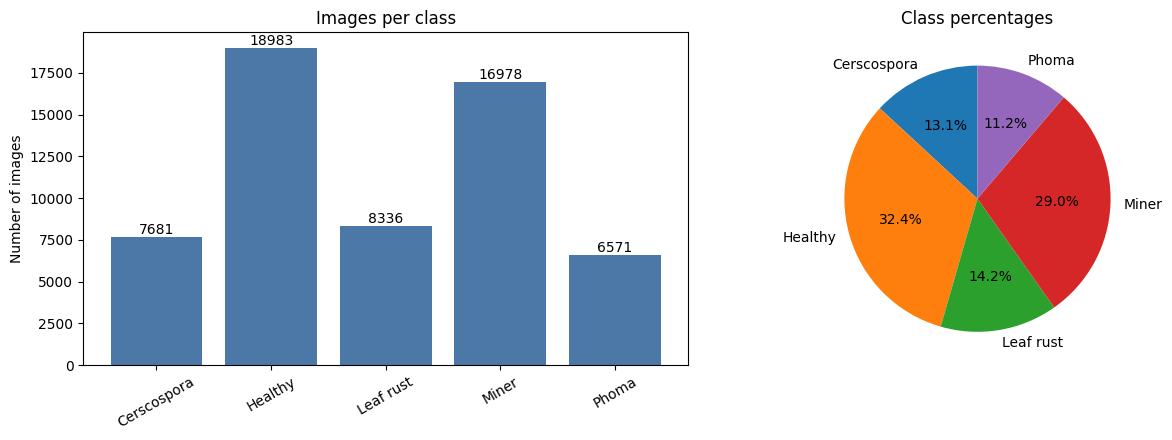

In [5]:
total_images = len(df)
per_class = df["class"].value_counts().reindex(class_names).fillna(0).astype(int)
class_table = pd.DataFrame({"images": per_class, "percent": (per_class / total_images * 100).round(2)})
class_table.loc["TOTAL"] = [total_images, 100.0]; class_table["images"] = class_table["images"].astype(int)
print(f"Total number of images : {total_images:,}"); print(f"Number of classes      : {NUM_CLASSES}")
print(f"Class names            : {class_names}\n"); display(class_table)
save_table(class_table, "41_images_per_class")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
bars = ax[0].bar(per_class.index, per_class.values, color="#4c78a8"); ax[0].bar_label(bars, fmt="%d")
ax[0].set_title("Images per class"); ax[0].set_ylabel("Number of images"); ax[0].tick_params(axis="x", rotation=30)
ax[1].pie(per_class.values, labels=per_class.index, autopct="%1.1f%%", startangle=90); ax[1].set_title("Class percentages")
plt.tight_layout(); save_fig("41_class_counts_and_percentages"); plt.show()

In [6]:
# Image dimensions, channels, true file format (headers only: fast)
meta = []
for p in tqdm(df["path"], desc="Reading image headers"):
    try:
        with Image.open(p) as im: meta.append((im.width, im.height, im.mode, im.format))
    except Exception:
        meta.append((None, None, None, None))
df[["width", "height", "mode", "true_format"]] = pd.DataFrame(meta, index=df.index)
unreadable = int(df["width"].isna().sum())
ok = df[df["width"].notna()].copy()
ok["width"] = ok["width"].astype(int); ok["height"] = ok["height"].astype(int)
ok["aspect_ratio"] = (ok["width"] / ok["height"]).round(3)
MODE_CHANNELS = {"1": 1, "L": 1, "P": 1, "I;16": 1, "I": 1, "F": 1, "LA": 2, "RGB": 3, "YCbCr": 3, "LAB": 3, "HSV": 3, "RGBA": 4, "CMYK": 4}
ok["channels"] = ok["mode"].map(MODE_CHANNELS)
print(f"Readable: {len(ok):,} | unreadable/corrupt (header level): {unreadable}")

ch_table = ok.groupby(["mode", "channels"], dropna=False).size().to_frame("images").reset_index()
ch_table["percent"] = (ch_table["images"] / len(ok) * 100).round(2)
print("\nColour modes / channels:"); display(ch_table); save_table(ch_table, "41_channels", index=False)

ext_counts = ok["extension"].value_counts().to_frame("images"); ext_counts["percent"] = (ext_counts["images"] / len(ok) * 100).round(2)
fmt_counts = ok["true_format"].value_counts().to_frame("images"); fmt_counts["percent"] = (fmt_counts["images"] / len(ok) * 100).round(2)
print("\nBy file extension:"); display(ext_counts)
print("By actual encoded format (from the header):"); display(fmt_counts)
save_table(ext_counts, "41_file_extensions"); save_table(fmt_counts, "41_true_formats")
EXT_TO_FORMAT = {".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG", ".bmp": "BMP", ".gif": "GIF", ".tif": "TIFF", ".tiff": "TIFF", ".webp": "WEBP"}
mismatch = ok[ok["extension"].map(EXT_TO_FORMAT) != ok["true_format"]]
print("Extension/format mismatches:", len(mismatch))

RESULTS["dataset_statistics"] = {"total_files": int(total_images), "num_classes": int(NUM_CLASSES), "class_names": class_names,
    "files_per_class": {k: int(v) for k, v in per_class.items()}, "unreadable_headers": unreadable,
    "colour_modes": {k: int(v) for k, v in ok["mode"].value_counts().items()},
    "extensions": {k: int(v) for k, v in ok["extension"].value_counts().items()},
    "extension_format_mismatches": int(len(mismatch))}
print("\n" + "=" * 55 + "\n4.1 SUMMARY\n" + "=" * 55)
for k, v in RESULTS["dataset_statistics"].items(): print(f"{k:28s}: {v}")

Reading image headers:   0%|          | 0/58549 [00:00<?, ?it/s]

Readable: 58,549 | unreadable/corrupt (header level): 0

Colour modes / channels:


,mode,channels,images,percent
0,RGB,3,58549,100.0


[saved table]  report_evidence/tables/41_channels.csv

By file extension:


,images,percent
extension,,
.jpg,58405,99.75
.jpeg,144,0.25


By actual encoded format (from the header):


,images,percent
true_format,,
JPEG,58549,100.0


[saved table]  report_evidence/tables/41_file_extensions.csv
[saved table]  report_evidence/tables/41_true_formats.csv
Extension/format mismatches: 0

4.1 SUMMARY
total_files                 : 58549
num_classes                 : 5
class_names                 : ['Cerscospora', 'Healthy', 'Leaf rust', 'Miner', 'Phoma']
files_per_class             : {'Cerscospora': 7681, 'Healthy': 18983, 'Leaf rust': 8336, 'Miner': 16978, 'Phoma': 6571}
unreadable_headers          : 0
colour_modes                : {'RGB': 58549}
extensions                  : {'.jpg': 58405, '.jpeg': 144}
extension_format_mismatches : 0


## 4.2 Class Distribution
**Imbalance ratio** = largest class ÷ smallest class. Thresholds (set in Part 1): ≤1.5 Balanced, ≤4.0 Moderately imbalanced, else Highly imbalanced. These are common rules of thumb, not an official standard — say so in the report.

[saved figure] report_evidence/figures/42_class_distribution.png


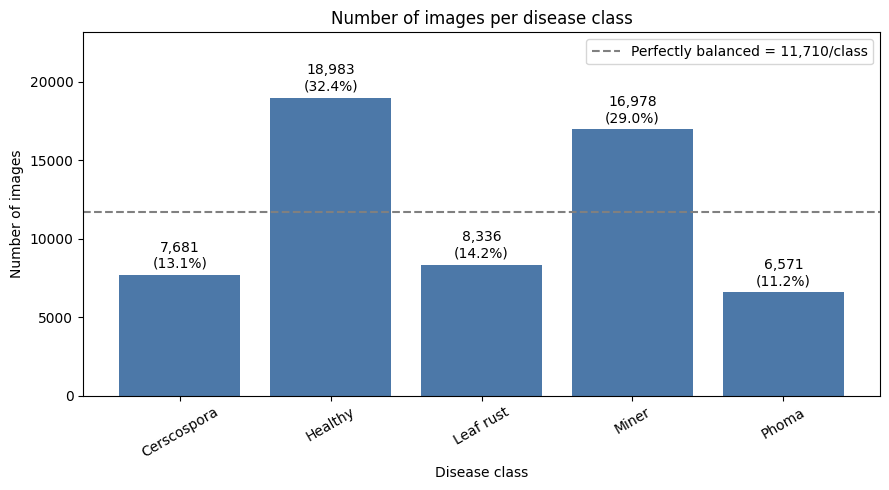

,images,percent,ratio_to_largest
class,,,
Cerscospora,7681,13.12,0.40
Healthy,18983,32.42,1.00
Leaf rust,8336,14.24,0.44
Miner,16978,29.00,0.89
Phoma,6571,11.22,0.35


[saved table]  report_evidence/tables/42_balance_table.csv
Imbalance ratio : 2.89  (largest Healthy = 18,983, smallest Phoma = 6,571)
VERDICT         : MODERATELY IMBALANCED

What this means for training:
 - Use class_weight='balanced' during training.
 - Use a stratified split.
 - Report macro-F1 and per-class recall, not just accuracy.


In [7]:
def assess_balance(counts):
    counts = counts.sort_index(); k, total = len(counts), int(counts.sum())
    ratio = float("inf") if counts.min() == 0 else counts.max() / counts.min()
    shares = counts / total; nz = shares[shares > 0]
    entropy = float(-(nz * np.log(nz)).sum() / np.log(k)) if k > 1 else 1.0
    cv = float(counts.std(ddof=0) / counts.mean())
    verdict = "Balanced" if ratio <= BALANCED_MAX else ("Moderately imbalanced" if ratio <= MODERATE_MAX else "Highly imbalanced")
    return {"verdict": verdict, "ratio": float(ratio), "entropy": entropy, "cv": cv, "total": total, "k": k,
            "largest": (counts.idxmax(), int(counts.max())), "smallest": (counts.idxmin(), int(counts.min())),
            "balanced_share": 100 / k, "smallest_share": float(shares.min() * 100)}

def plot_class_distribution(counts, title, ax):
    counts = counts.sort_index(); mean = counts.mean()
    colors = ["#e45756" if c < 0.5 * mean else "#4c78a8" for c in counts.values]
    bars = ax.bar(counts.index, counts.values, color=colors)
    ax.bar_label(bars, labels=[f"{c:,}\n({c / counts.sum() * 100:.1f}%)" for c in counts.values], padding=3)
    ax.axhline(mean, color="gray", ls="--", label=f"Perfectly balanced = {mean:,.0f}/class")
    ax.set_title(title); ax.set_ylabel("Number of images"); ax.set_xlabel("Disease class")
    ax.tick_params(axis="x", rotation=30); ax.set_ylim(0, counts.max() * 1.22); ax.legend(loc="upper right")

fig, ax = plt.subplots(figsize=(9, 5))
plot_class_distribution(per_class, "Number of images per disease class", ax)
plt.tight_layout(); save_fig("42_class_distribution"); plt.show()

res_balance = assess_balance(per_class)
table = pd.DataFrame({"images": per_class, "percent": (per_class / per_class.sum() * 100).round(2),
                      "ratio_to_largest": (per_class / per_class.max()).round(2)})
display(table); save_table(table, "42_balance_table")
print(f"Imbalance ratio : {res_balance['ratio']:.2f}  (largest {res_balance['largest'][0]} = {res_balance['largest'][1]:,}, "
      f"smallest {res_balance['smallest'][0]} = {res_balance['smallest'][1]:,})")
print(f"VERDICT         : {res_balance['verdict'].upper()}")
advice = {
    "Balanced": ["Accuracy is reasonable, but still report per-class precision/recall/F1.", "class_weight is optional."],
    "Moderately imbalanced": ["Use class_weight='balanced' during training.", "Use a stratified split.", "Report macro-F1 and per-class recall, not just accuracy."],
    "Highly imbalanced": ["Accuracy alone is misleading.", "Use class_weight and/or targeted augmentation for minority classes (Phase 13).", "Report macro-F1, per-class recall and the confusion matrix.", "Collect more images for the smallest classes if possible."],
}
print("\nWhat this means for training:")
for line in advice[res_balance["verdict"]]: print(" -", line)
RESULTS["class_balance"] = res_balance

## 4.3 Image Visualization — representative samples from every class

[saved figure] report_evidence/figures/43_sample_images_per_class.png


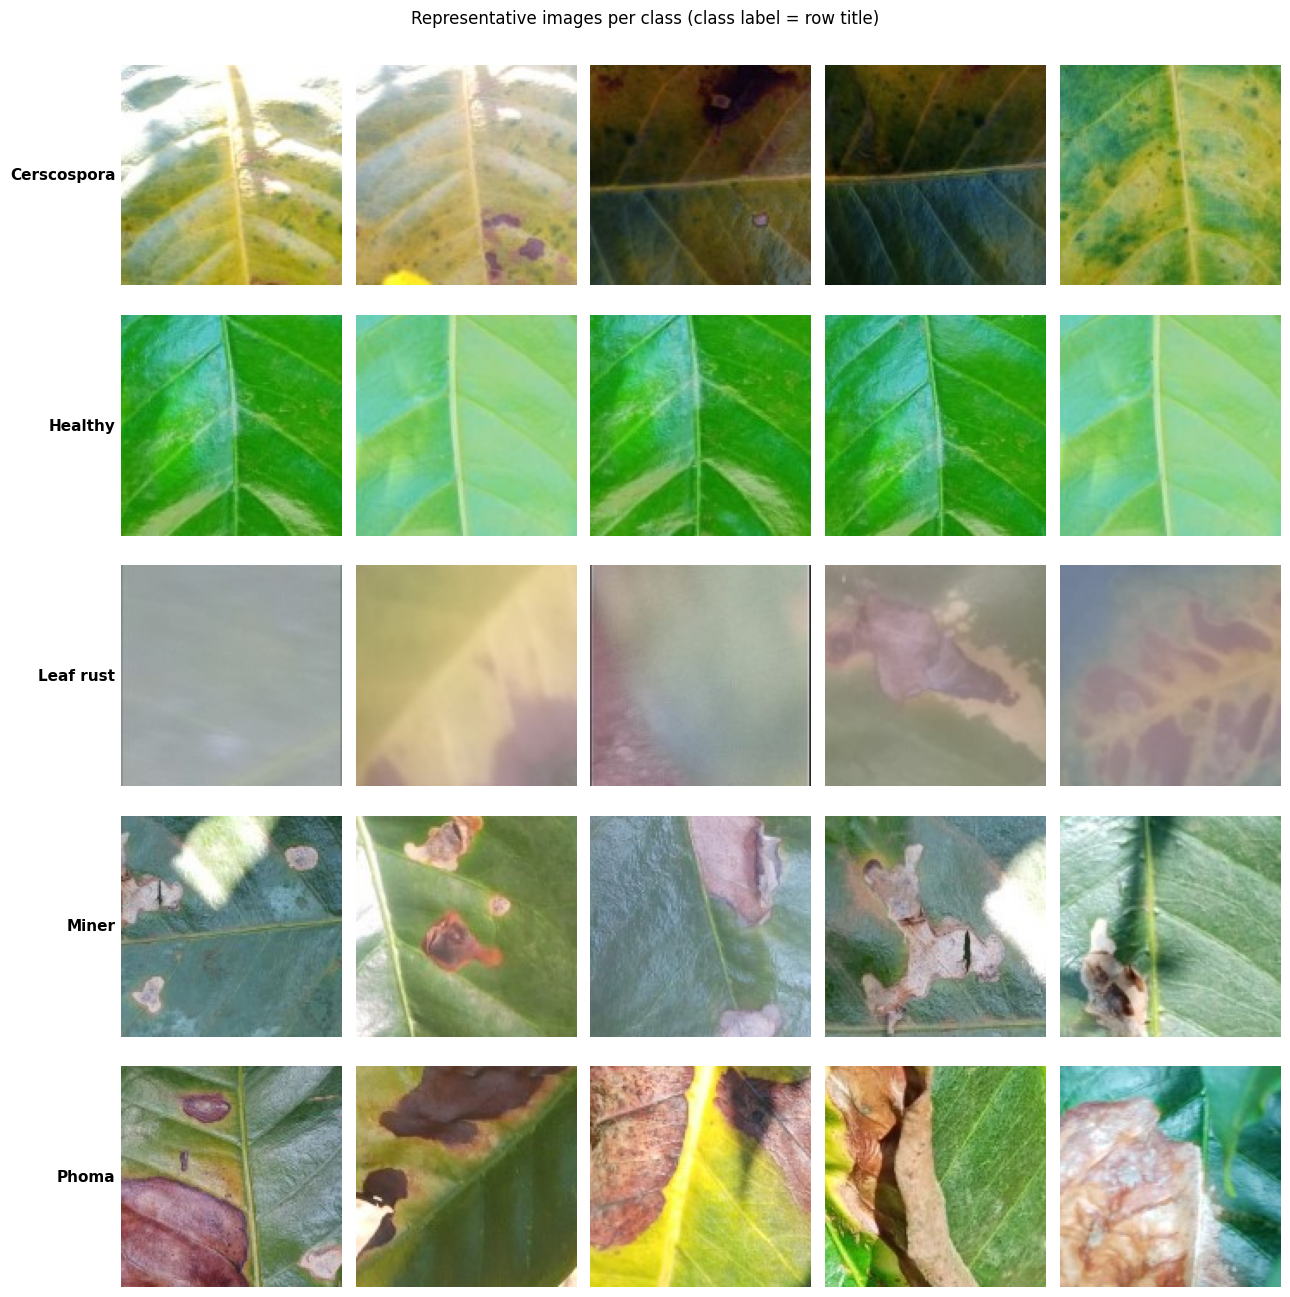

In [8]:
N_SAMPLES = 5
fig, axes = plt.subplots(NUM_CLASSES, N_SAMPLES, figsize=(2.6 * N_SAMPLES, 2.6 * NUM_CLASSES))
axes = np.atleast_2d(axes)
for r, c in enumerate(class_names):
    sub = df[df["class"] == c]["path"]
    picks = sub.sample(min(N_SAMPLES, len(sub)), random_state=SEED).tolist()
    for k in range(N_SAMPLES):
        ax = axes[r, k]; ax.axis("off")
        if k < len(picks):
            ax.imshow(Image.open(picks[k]).convert("RGB"))
        if k == 0:
            ax.set_ylabel(c, rotation=0, ha="right", va="center", fontsize=11, fontweight="bold")
            ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values(): spine.set_visible(False)
plt.suptitle("Representative images per class (class label = row title)", y=1.0)
plt.tight_layout(); save_fig("43_sample_images_per_class"); plt.show()

## 4.4 Image Dimension Analysis

,width,height,aspect_ratio
min,74.00,87.00,0.29
max,256.00,256.00,2.94
mean,129.49,132.03,1.00
median,128.00,128.00,1.00
std,17.16,23.21,0.20


[saved table]  report_evidence/tables/44_dimension_summary.csv
Distinct (width x height) sizes: 49
Images have DIFFERENT resolutions. Most common sizes:


,,images,percent
width,height,,
128,128,55596,94.96
122,256,224,0.38
113,256,128,0.22
92,256,128,0.22
256,120,128,0.22
116,256,128,0.22
94,256,128,0.22
256,125,128,0.22
104,256,120,0.20


[saved table]  report_evidence/tables/44_most_common_sizes.csv
[saved figure] report_evidence/figures/44_dimension_histograms.png


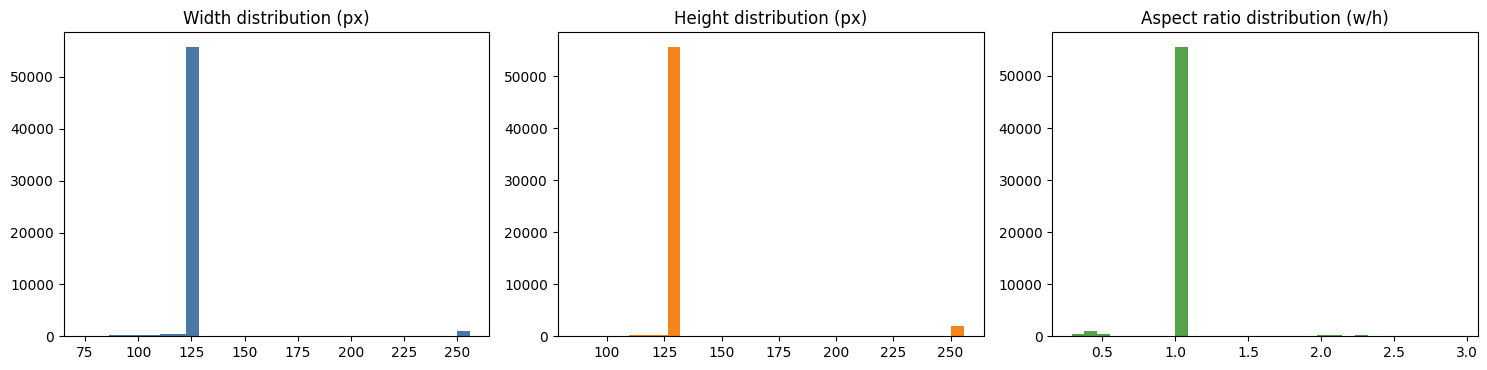

width             height             aspect_ratio              
              min median  max    min median  max          min median    max
class                                                                      
Cerscospora    83  128.0  256     99  128.0  256        0.359    1.0  2.586
Healthy       128  128.0  128    128  128.0  128        1.000    1.0  1.000
Leaf rust     128  128.0  128    128  128.0  128        1.000    1.0  1.000
Miner          74  128.0  256     87  128.0  256        0.289    1.0  2.943
Phoma         128  128.0  128    128  128.0  128        1.000    1.0  1.000

[saved table]  report_evidence/tables/44_dimensions_per_class.csv


In [9]:
dim_summary = ok[["width", "height", "aspect_ratio"]].agg(["min", "max", "mean", "median", "std"]).round(2)
display(dim_summary); save_table(dim_summary, "44_dimension_summary")

size_counts = ok.groupby(["width", "height"]).size().sort_values(ascending=False)
print(f"Distinct (width x height) sizes: {len(size_counts)}")
if len(size_counts) == 1:
    print("All images share one resolution: %d x %d -> resizing is still required before batching, but no resampling artifacts from mixed native sizes." % size_counts.index[0])
else:
    top = size_counts.head(10).to_frame("images"); top["percent"] = (top["images"] / len(ok) * 100).round(2)
    print("Images have DIFFERENT resolutions. Most common sizes:"); display(top); save_table(top, "44_most_common_sizes")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(ok["width"], bins=30, color="#4c78a8"); ax[0].set_title("Width distribution (px)")
ax[1].hist(ok["height"], bins=30, color="#f58518"); ax[1].set_title("Height distribution (px)")
ax[2].hist(ok["aspect_ratio"], bins=30, color="#54a24b"); ax[2].set_title("Aspect ratio distribution (w/h)")
plt.tight_layout(); save_fig("44_dimension_histograms"); plt.show()

dims_per_class = ok.groupby("class")[["width", "height", "aspect_ratio"]].agg(["min", "median", "max"])
display(dims_per_class); save_table(dims_per_class, "44_dimensions_per_class")
RESULTS["dimension_analysis"] = {"distinct_sizes": int(len(size_counts)),
    "width_min_median_max": [int(ok.width.min()), int(ok.width.median()), int(ok.width.max())],
    "height_min_median_max": [int(ok.height.min()), int(ok.height.median()), int(ok.height.max())]}

## 4.5 Image Quality Analysis

Checks, each producing a boolean flag column on the image index:

| Flag | How it is detected |
|---|---|
| `corrupt` | file cannot be opened / decoded |
| `extreme_dark` / `extreme_bright` | mean pixel intensity outside the thresholds in Part 1 |
| `blurred` | variance of the Laplacian below the threshold (lower variance = blurrier) |
| `exact_duplicate` | identical file content (MD5 hash) |
| `near_duplicate_group` | same or flipped image, detected by a perceptual hash (catches re-saved/renamed copies that MD5 misses) |
| `possibly_no_leaf` | very low share of green/brown "leaf-like" pixels — a **heuristic**, not proof |
| `possible_mislabel` | color histogram is a statistical outlier inside its class — a **heuristic that flags for human review**, it never removes automatically |

**Only the first three plus exact/near duplicates are removed automatically (Phase 5)** — they are objective and safe. Blur, brightness, "no-leaf" and "possible mislabel" are **flagged and then manually reviewed** (next cell shows a sample), because the guideline is explicit: *do not remove images simply because they look different*.

Quality checks:   0%|          | 0/58549 [00:00<?, ?it/s]

Flag counts (may overlap):


,images
corrupt,0
extreme_dark,0
extreme_bright,0
blurred,18984
possibly_no_leaf,272


[saved table]  report_evidence/tables/45_quality_flag_counts.csv
[saved figure] report_evidence/figures/45_quality_histograms.png


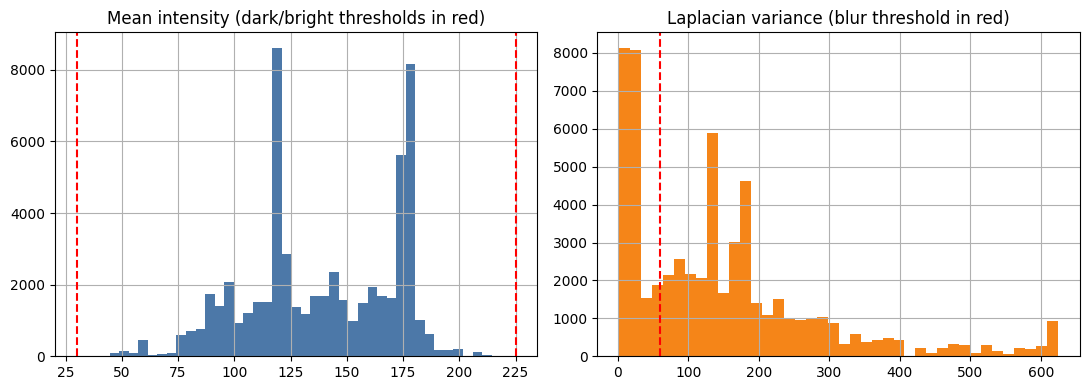

In [10]:
def laplacian_variance(gray_arr):
    if cv2 is not None:
        return float(cv2.Laplacian(gray_arr, cv2.CV_64F).var())
    k = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float64)
    from scipy.signal import convolve2d
    lap = convolve2d(gray_arr.astype(np.float64), k, mode="valid")
    return float(lap.var())

def green_fraction(rgb_arr):
    r, g, b = rgb_arr[..., 0].astype(int), rgb_arr[..., 1].astype(int), rgb_arr[..., 2].astype(int)
    leafish = (g > r) & (g > 60) | ((r > g) & (r > b) & (r < 160) & (g > 40))   # green OR brown/dried-leaf tones
    return float(leafish.mean())

quality_rows = []
for p, c in tqdm(list(zip(df["path"], df["class"])), desc="Quality checks"):
    try:
        with Image.open(p) as im:
            im.draft("RGB", (256, 256))
            rgb = np.asarray(im.convert("RGB").resize((160, 160)))
        gray = np.asarray(Image.fromarray(rgb).convert("L"))
        quality_rows.append({"path": p, "class": c, "corrupt": False, "mean_intensity": float(gray.mean()),
                             "laplacian_var": laplacian_variance(gray), "green_fraction": green_fraction(rgb)})
    except Exception:
        quality_rows.append({"path": p, "class": c, "corrupt": True, "mean_intensity": np.nan, "laplacian_var": np.nan, "green_fraction": np.nan})

qual = pd.DataFrame(quality_rows)
qual["extreme_dark"] = qual["mean_intensity"] < DARK_MEAN_THRESHOLD
qual["extreme_bright"] = qual["mean_intensity"] > BRIGHT_MEAN_THRESHOLD
qual["blurred"] = qual["laplacian_var"] < BLUR_VARIANCE_THRESHOLD
qual["possibly_no_leaf"] = qual["green_fraction"] < GREEN_PIXEL_MIN_FRACTION

flag_counts = qual[["corrupt", "extreme_dark", "extreme_bright", "blurred", "possibly_no_leaf"]].sum()
print("Flag counts (may overlap):"); display(flag_counts.to_frame("images"))
save_table(flag_counts.to_frame("images"), "45_quality_flag_counts")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
qual["mean_intensity"].hist(bins=40, ax=ax[0], color="#4c78a8")
ax[0].axvline(DARK_MEAN_THRESHOLD, color="red", ls="--"); ax[0].axvline(BRIGHT_MEAN_THRESHOLD, color="red", ls="--")
ax[0].set_title("Mean intensity (dark/bright thresholds in red)")
qual["laplacian_var"].clip(upper=qual["laplacian_var"].quantile(0.99)).hist(bins=40, ax=ax[1], color="#f58518")
ax[1].axvline(BLUR_VARIANCE_THRESHOLD, color="red", ls="--"); ax[1].set_title("Laplacian variance (blur threshold in red)")
plt.tight_layout(); save_fig("45_quality_histograms"); plt.show()

In [11]:
# --- duplicates (exact via MD5, near-duplicate/flipped via perceptual hash) ---
hashes, dhashes = [], []
for p in tqdm(df["path"], desc="Hashing (exact + perceptual)"):
    md5_val, dhash_val = None, None
    try:
        with open(p, "rb") as fh:
            md5_val = hashlib.md5(fh.read()).hexdigest()
    except Exception:
        pass
    try:
        with Image.open(p) as im:
            im.draft("L", (128, 128))
            g = im.convert("L").resize((9, 8), Image.BILINEAR)
        a = np.asarray(g, dtype=np.int16)
        vals = []
        for arr in (a, a[:, ::-1], a[::-1, :], a[::-1, ::-1]):
            bits = (arr[:, 1:] > arr[:, :-1]).flatten()
            vals.append(int("".join("1" if b else "0" for b in bits), 2))
        dhash_val = min(vals)
    except Exception:
        pass
    hashes.append(md5_val); dhashes.append(dhash_val)
qual["md5"] = hashes
qual["dhash"] = dhashes
qual["exact_duplicate"] = qual.duplicated(subset=["class", "md5"], keep="first") & qual["md5"].notna()
qual["near_duplicate_group"] = qual.duplicated(subset=["class", "dhash"], keep="first") & qual["dhash"].notna() & ~qual["exact_duplicate"]

# --- possible mislabels: color-histogram outlier within its OWN class (flag for review only) ---
def color_hist(path, bins=8):
    try:
        with Image.open(path) as im:
            im.draft("RGB", (96, 96)); a = np.asarray(im.convert("RGB").resize((64, 64)))
        h = [np.histogram(a[..., ch], bins=bins, range=(0, 255))[0] for ch in range(3)]
        h = np.concatenate(h).astype(float)
        return h / (h.sum() + 1e-9)
    except Exception:
        return None   # corrupt / unreadable -> excluded from the outlier check below

feats_list = [color_hist(p) for p in tqdm(df["path"], desc="Color histograms")]
qual["possible_mislabel"] = False
for c in class_names:
    idx = np.where((df["class"] == c).values)[0]
    idx = np.array([i for i in idx if feats_list[i] is not None])   # drop corrupt files from this check
    if len(idx) < 5: continue
    class_feats = np.stack([feats_list[i] for i in idx])
    centroid = class_feats.mean(axis=0)
    dist = np.linalg.norm(class_feats - centroid, axis=1)
    cutoff = np.percentile(dist, OUTLIER_PERCENTILE)
    qual.loc[qual.index[idx][dist >= cutoff], "possible_mislabel"] = True

print("Exact duplicates      :", int(qual["exact_duplicate"].sum()))
print("Near-duplicate/flipped :", int(qual["near_duplicate_group"].sum()))
print("Possible mislabels (review only):", int(qual["possible_mislabel"].sum()), f"(top {100 - OUTLIER_PERCENTILE}% farthest from class centroid)")
save_table(qual.drop(columns=["md5", "dhash"]), "45_quality_flags_full", index=False)

Hashing (exact + perceptual):   0%|          | 0/58549 [00:00<?, ?it/s]

Color histograms:   0%|          | 0/58549 [00:00<?, ?it/s]

Exact duplicates      : 54793
Near-duplicate/flipped : 2521
Possible mislabels (review only): 730 (top 1% farthest from class centroid)
[saved table]  report_evidence/tables/45_quality_flags_full.csv


### Manual review of the "flag-only" categories
Look at a small sample from each soft-flag category before deciding anything. This cell only **displays** images — it does not remove any.

[saved figure] report_evidence/figures/45_review_blurred.png


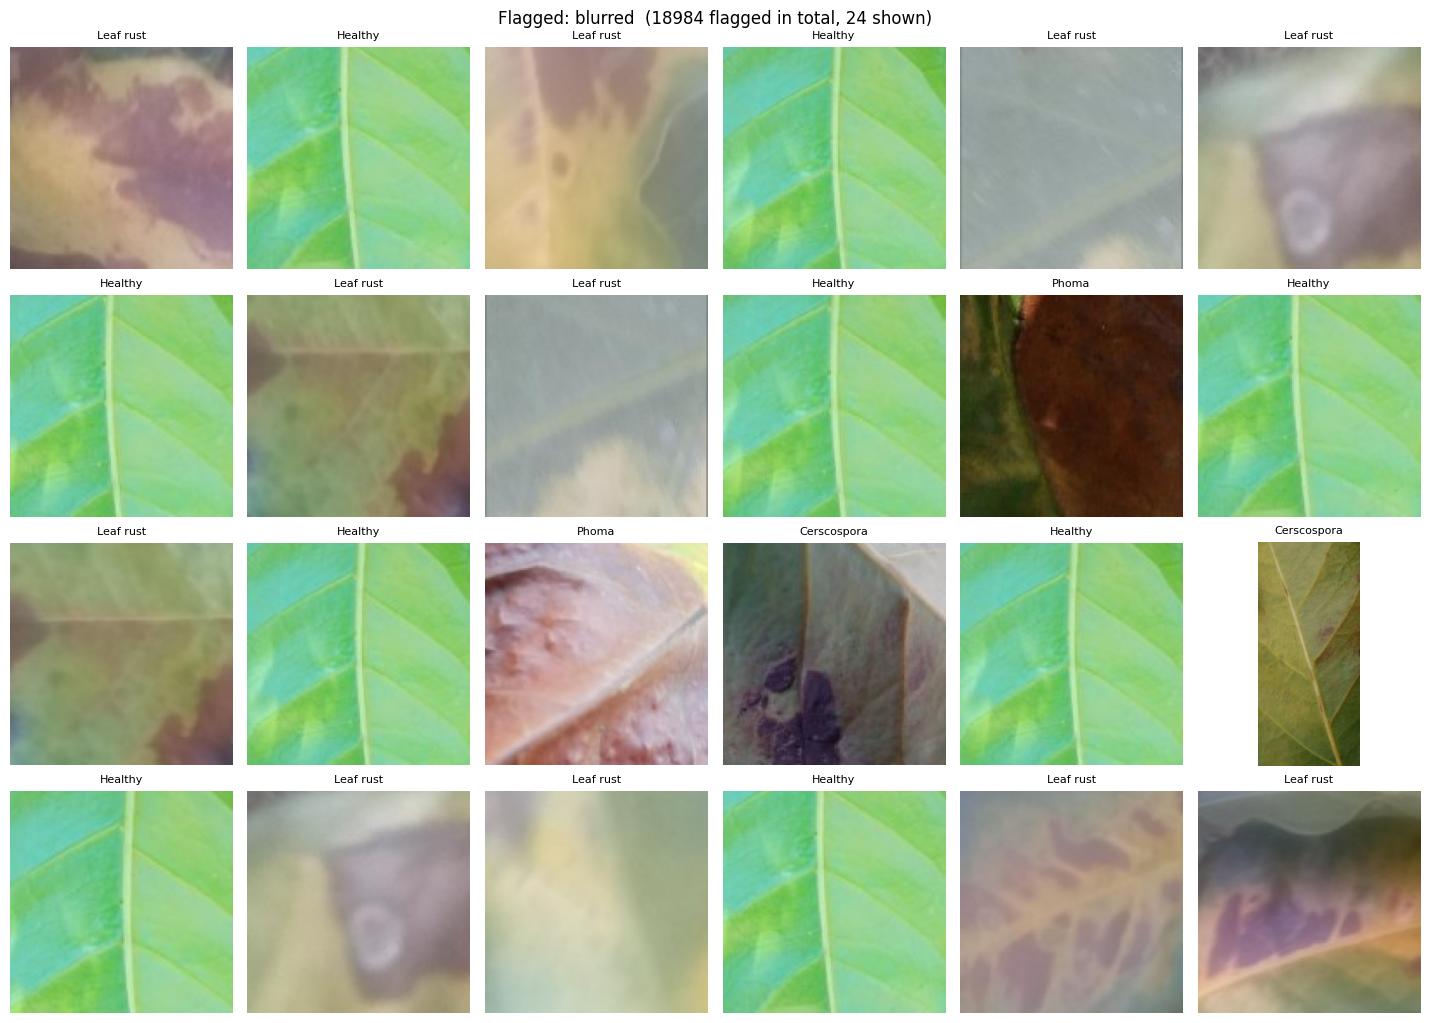

No images flagged as 'extreme_dark'.
No images flagged as 'extreme_bright'.
[saved figure] report_evidence/figures/45_review_possibly_no_leaf.png


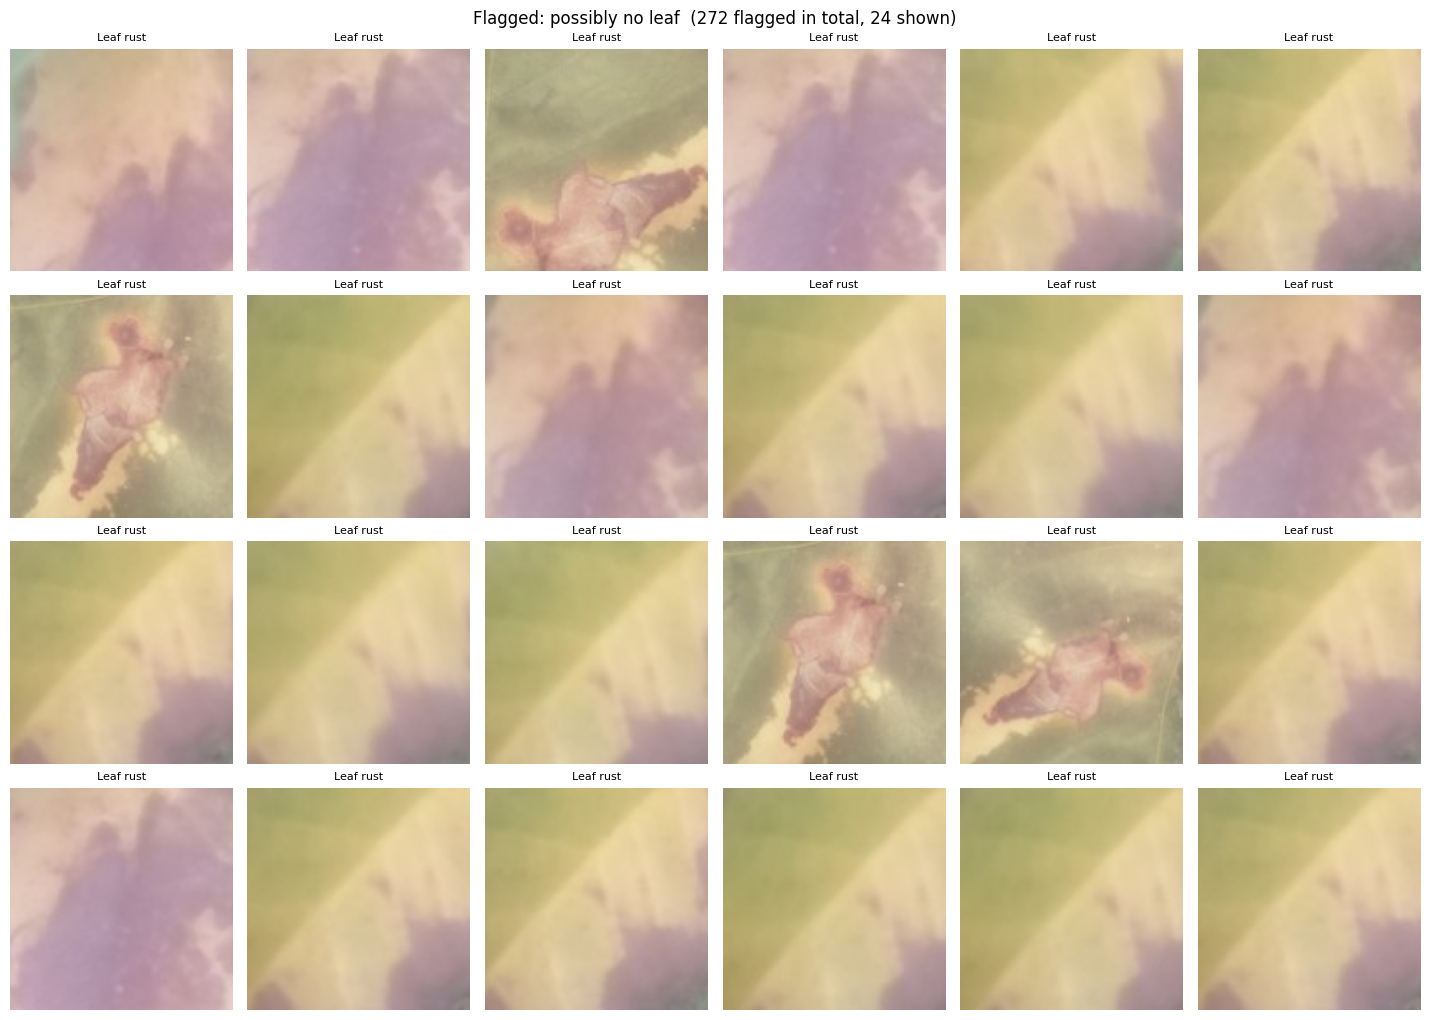

[saved figure] report_evidence/figures/45_review_possible_mislabel.png


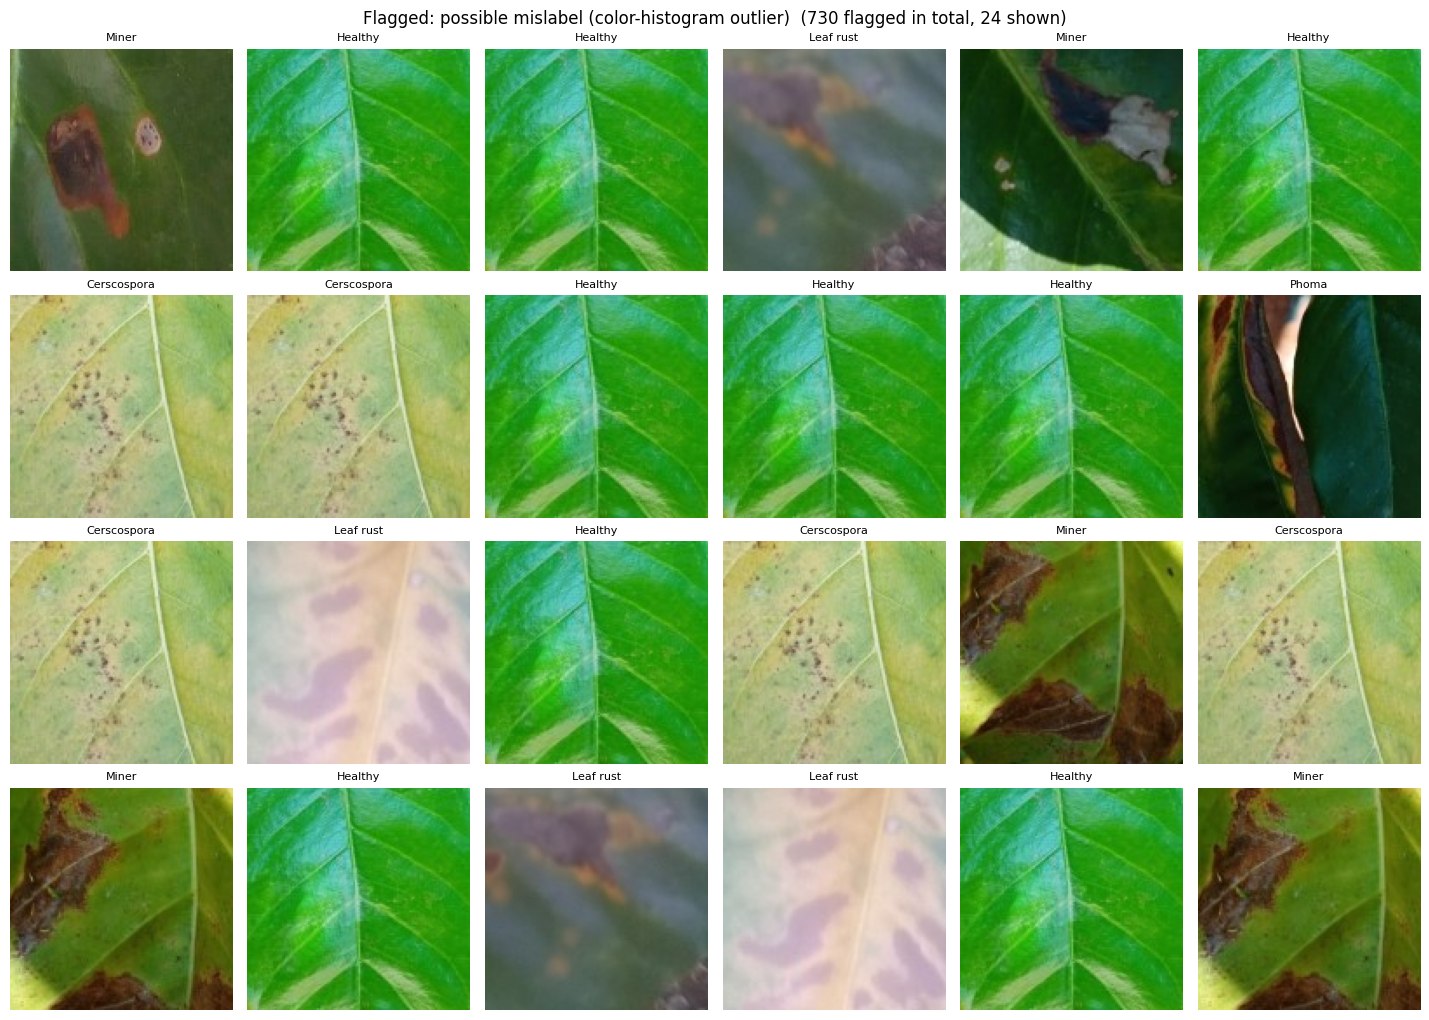


After looking at the samples above, decide in the report whether the thresholds in Part 1
need adjusting, and whether any flagged images should be removed by hand.


In [12]:
def show_flag_sample(flag_col, title):
    hits = qual[qual[flag_col] & ~qual["corrupt"]]
    if not len(hits):
        print(f"No images flagged as '{flag_col}'."); return
    sample = hits.sample(min(MANUAL_REVIEW_SAMPLE_SIZE, len(hits)), random_state=SEED)
    cols = 6; rws = int(np.ceil(len(sample) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(2.4 * cols, 2.6 * rws)); axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, (_, row) in zip(axes, sample.iterrows()):
        ax.imshow(Image.open(row["path"]).convert("RGB")); ax.set_title(row["class"], fontsize=8)
    plt.suptitle(f"{title}  ({len(hits)} flagged in total, {len(sample)} shown)")
    plt.tight_layout(); save_fig(f"45_review_{flag_col}"); plt.show()

for flag, title in [("blurred", "Flagged: blurred"), ("extreme_dark", "Flagged: extremely dark"),
                    ("extreme_bright", "Flagged: extremely bright"), ("possibly_no_leaf", "Flagged: possibly no leaf"),
                    ("possible_mislabel", "Flagged: possible mislabel (color-histogram outlier)")]:
    show_flag_sample(flag, title)

print("\nAfter looking at the samples above, decide in the report whether the thresholds in Part 1")
print("need adjusting, and whether any flagged images should be removed by hand.")

## Phase 5 — Data Cleaning

Applies the `AUTO_REMOVE` decisions from Part 1. By default only the **objective** problems are removed automatically: corrupt files, exact duplicates, and near-duplicate/flipped copies. Blur, brightness, "no-leaf" and "possible mislabel" stay in the dataset unless you changed `AUTO_REMOVE` after reviewing the samples above — removing based on appearance alone risks throwing away real, harder examples.

Also verifies: every class folder is non-empty and every image has a valid class label (guaranteed by construction here, since the label comes from the folder name) — flags any class with suspiciously few images.

In [13]:
remove_mask = pd.Series(False, index=qual.index)
reasons = {"corrupt": "corrupt", "exact_duplicate": "exact_duplicate", "near_duplicate_group": "near_duplicate_group",
          "blurred": "blurred", "extreme_dark": "extreme_dark", "extreme_bright": "extreme_bright",
          "possibly_no_leaf": "possibly_no_leaf", "possible_mislabel": "possible_mislabel"}
removed_by = {}
for flag, auto in AUTO_REMOVE.items():
    if auto and flag in qual.columns:
        this_mask = qual[flag] & ~remove_mask
        removed_by[flag] = int(this_mask.sum())
        remove_mask |= qual[flag]

cleaning = pd.DataFrame({"criterion": list(AUTO_REMOVE.keys()),
                         "auto_removed": [AUTO_REMOVE[k] for k in AUTO_REMOVE],
                         "images_removed": [removed_by.get(k, 0) for k in AUTO_REMOVE]})
display(cleaning); save_table(cleaning, "phase5_cleaning_summary", index=False)

data = df.loc[qual.index[~remove_mask]].copy().reset_index(drop=True)
data["label"] = data["class"].map(label_of).astype(int)
print(f"\nImages before cleaning: {len(df):,} | after cleaning: {len(data):,} ({len(data) / len(df) * 100:.1f}% kept)")

per_class_after = data["class"].value_counts().reindex(class_names).fillna(0).astype(int)
verify = pd.DataFrame({"before": per_class, "after": per_class_after})
verify["removed"] = verify["before"] - verify["after"]
display(verify); save_table(verify, "phase5_before_after_per_class")
if (per_class_after < 20).any():
    print("WARNING: at least one class now has very few images (<20) — check the table above.")
RESULTS["cleaning"] = {"before": int(len(df)), "after": int(len(data)), "removed_by": removed_by}

,criterion,auto_removed,images_removed
0,corrupt,True,0
1,exact_duplicate,True,54793
2,near_duplicate_group,False,0
3,blurred,False,0
4,extreme_dark,False,0
5,extreme_bright,False,0
6,possibly_no_leaf,False,0
7,possible_mislabel,False,0


[saved table]  report_evidence/tables/phase5_cleaning_summary.csv

Images before cleaning: 58,549 | after cleaning: 3,756 (6.4% kept)


,before,after,removed
class,,,
Cerscospora,7681,322,7359
Healthy,18983,62,18921
Leaf rust,8336,1042,7294
Miner,16978,1639,15339
Phoma,6571,691,5880


[saved table]  report_evidence/tables/phase5_before_after_per_class.csv


## Phase 6 — Train / Validation / Test Split

Target ratios come from `SPLIT_RATIOS` in Part 1 (default 70/15/15). Images are grouped first (by file-name-without-augmentation-markers **and** by the perceptual hash computed in Part 9, so exact and flipped/renamed copies fall in the same group), then **whole groups** are assigned to a split with a greedy, per-class-stratified algorithm that keeps each split close to its target ratio **within every class**. No group (and therefore no augmented copy of an original image) is ever split across train/validation/test — this is what prevents data leakage.

In [14]:
AUG_PATTERN = re.compile(r"([_\-\s]?(aug|augmented|flip|flipped|rot|rotate|rotated|mirror|copy|crop|zoom|noise|bright)[_\-]?\d*|\s*\(\d+\))$", re.I)
def name_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    prev = None
    while prev != stem:
        prev = stem; stem = AUG_PATTERN.sub("", stem)
    return stem if stem else os.path.basename(path)

qual_idx = qual.set_index(qual["path"])
data["name_key"] = data["class"] + "|" + data["path"].apply(name_key)
data["dhash"] = data["path"].map(qual_idx["dhash"])
data["hash_key"] = data["class"] + "|" + data["dhash"].astype(str)

def group_with(keys_list):
    parent = list(range(len(data)))
    def find(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb: parent[rb] = ra
    seen = {}
    for i in range(len(data)):
        for keys in keys_list:
            k = keys[i]
            if k in seen: union(i, seen[k])
            else: seen[k] = i
    return [find(i) for i in range(len(data))]

# Safety check: perceptual-hash grouping can over-match on visually homogeneous close-up leaf photos.
# Compare grouping with name-key only vs name-key + perceptual hash; if adding the hash collapses the
# data far more aggressively (many unrelated images sharing one hash), it is not trustworthy here and is
# switched off automatically -- the split then relies on the (safer, always-legitimate) file-name grouping.
groups_name_only = group_with([data["name_key"].values])
n_groups_name_only = len(set(groups_name_only))
groups_with_hash = group_with([data["name_key"].values, data["hash_key"].values])
n_groups_with_hash = len(set(groups_with_hash))

USE_HASH_GROUPING = n_groups_with_hash >= 0.5 * n_groups_name_only
if USE_HASH_GROUPING:
    data["group"] = groups_with_hash
    print(f"Perceptual-hash grouping looks reliable here (groups: {n_groups_with_hash:,} vs {n_groups_name_only:,} name-only) -> using it.")
else:
    data["group"] = groups_name_only
    print(f"WARNING: perceptual-hash grouping collapsed the data far more than expected "
          f"({n_groups_with_hash:,} groups vs {n_groups_name_only:,} from file names alone).")
    print("         This usually means the images are too visually similar / too small for this hash to be reliable.")
    print("         Falling back to file-name-based grouping only for the split (near_duplicate_group flags remain informational).")

n_groups = data["group"].nunique()
print(f"Images: {len(data):,} | groups used for the split: {n_groups:,} | largest group: {int(data['group'].value_counts().max())} images")

         This usually means the images are too visually similar / too small for this hash to be reliable.
         Falling back to file-name-based grouping only for the split (near_duplicate_group flags remain informational).
Images: 3,756 | groups used for the split: 79 | largest group: 1639 images


Leakage check passed: no group appears in more than one split.



,train,validation,test,total
class,,,,
Cerscospora,236,44,42,322
Healthy,44,18,0,62
Leaf rust,774,137,131,1042
Miner,1639,0,0,1639
Phoma,510,91,90,691
TOTAL,3203,290,263,3756


[saved table]  report_evidence/tables/phase6_split_summary.csv
train 3,203 (85.3%) | validation 290 (7.7%) | test 263 (7.0%)   (target {'train': 0.7, 'validation': 0.15, 'test': 0.15})
[saved figure] report_evidence/figures/phase6_split_proportions.png


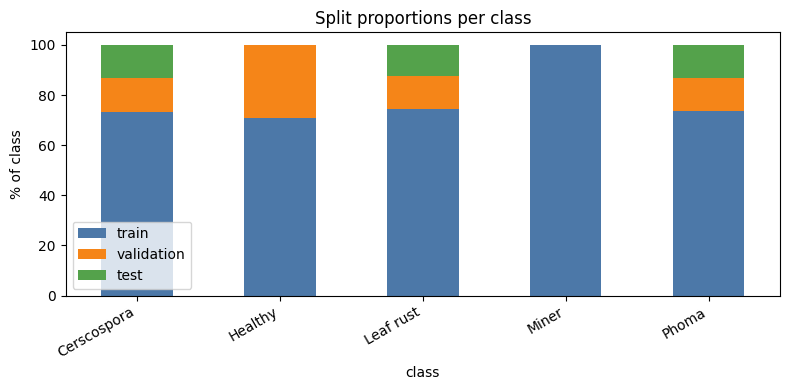

In [15]:
# Greedy, per-class-stratified group assignment to hit SPLIT_RATIOS as closely as possible
rng = random.Random(SEED)
split_names = list(SPLIT_RATIOS.keys())
assigned = {}                                    # group_id -> split name
running_count = {c: {s: 0 for s in split_names} for c in class_names}
target_count = {c: {s: SPLIT_RATIOS[s] * per_class_after[c] for s in split_names} for c in class_names}

groups_by_class = data.groupby("class")["group"].apply(lambda s: sorted(set(s)))
for c in class_names:
    gids = groups_by_class.get(c, [])
    gids_sizes = [(g, (data["group"] == g).sum()) for g in gids]
    rng.shuffle(gids_sizes)
    gids_sizes.sort(key=lambda x: -x[1])          # place larger groups first for a tighter fit
    for g, size in gids_sizes:
        deficits = {s: target_count[c][s] - running_count[c][s] for s in split_names}
        best_split = max(deficits, key=deficits.get)
        assigned[g] = best_split
        running_count[c][best_split] += size

data["split"] = data["group"].map(assigned)
train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df = data[data["split"] == "validation"].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

for a_name, a in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for b_name, b in [("train", train_df), ("val", val_df), ("test", test_df)]:
        if a_name < b_name:
            assert not (set(a.group) & set(b.group)), f"group overlap between {a_name} and {b_name}"
print("Leakage check passed: no group appears in more than one split.\n")

split_summary = pd.DataFrame({"train": train_df["class"].value_counts(), "validation": val_df["class"].value_counts(),
                              "test": test_df["class"].value_counts()}).reindex(class_names).fillna(0).astype(int)
split_summary["total"] = split_summary.sum(axis=1); split_summary.loc["TOTAL"] = split_summary.sum()
display(split_summary); save_table(split_summary, "phase6_split_summary")
print(f"train {len(train_df):,} ({len(train_df)/len(data)*100:.1f}%) | "
      f"validation {len(val_df):,} ({len(val_df)/len(data)*100:.1f}%) | "
      f"test {len(test_df):,} ({len(test_df)/len(data)*100:.1f}%)   (target {SPLIT_RATIOS})")

pct = split_summary.drop(index="TOTAL")[["train", "validation", "test"]]
pct = pct.div(pct.sum(axis=1), axis=0) * 100
pct.plot(kind="bar", stacked=True, figsize=(8, 4), color=["#4c78a8", "#f58518", "#54a24b"])
plt.ylabel("% of class"); plt.title("Split proportions per class"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); save_fig("phase6_split_proportions"); plt.show()

data[["path", "class", "label", "group", "split"]].to_csv(f"{EVIDENCE_DIR}/tables/split_assignment.csv", index=False)
RESULTS["split"] = {"train": len(train_df), "validation": len(val_df), "test": len(test_df), "target_ratios": SPLIT_RATIOS}

## Phase 7 — Image Preprocessing
Load → convert to RGB → resize to `IMG_SIZE` → tensor → normalize. **Normalization is architecture-specific** (Part 15 applies each backbone's own `preprocess_input`, matching what it saw during ImageNet pretraining), so this step only resizes and keeps raw 0–255 values; scaling happens inside each model.

In [16]:
AUTOTUNE = tf.data.AUTOTUNE
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # always RGB
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)                                  # float32, values 0-255
    return img, label

## Phase 8 — Data Augmentation
Applied to the **training set only**. Vertical flip is included but should be judged against real coffee-leaf photos before you rely on it: leaves are usually photographed a consistent way up, so decide in the report whether it is biologically reasonable for your data (toggle `VERTICAL_FLIP` below if not).

[saved figure] report_evidence/figures/phase8_augmentation_preview.png


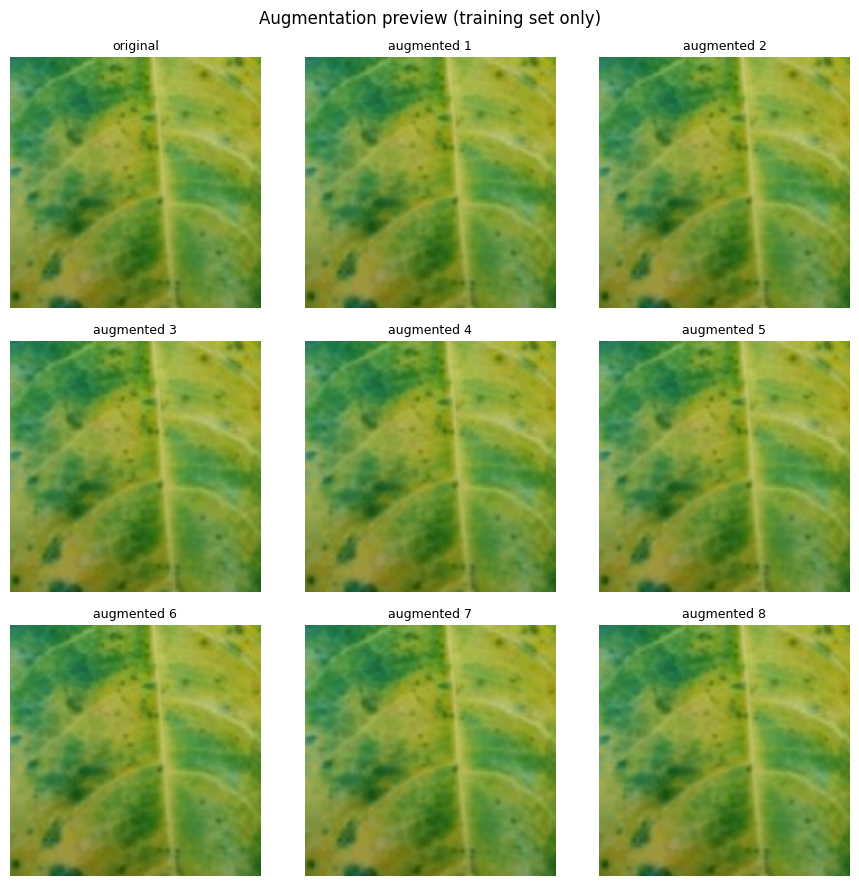

Class weights (Phase 13 - Option 1): {'Cerscospora': 2.71, 'Healthy': 14.56, 'Leaf rust': 0.83, 'Miner': 0.39, 'Phoma': 1.26}
Phase 13 - Option 2 (extra augmentation for minority classes) is available by raising RandomZoom/RandomRotation
           ranges above, or by duplicating minority-class TRAIN rows before batching, if class_weight alone is not enough.


In [19]:
VERTICAL_FLIP = True    # set False if upside-down leaves are not realistic for your photos

flip_mode = "horizontal_and_vertical" if VERTICAL_FLIP else "horizontal"
augment = tf.keras.Sequential([
    layers.RandomFlip(flip_mode),
    layers.RandomRotation(0.15),          # small rotations
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),   # translation
    layers.RandomBrightness(0.25, value_range=(0, 255)),
    layers.RandomContrast(0.25),
], name="augmentation")

def make_ds(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label"].values.astype("int32")))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

img, _ = load_image(train_df["path"].iloc[0], 0)
plt.figure(figsize=(9, 9))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
   # shown = img if i == 0 else augment(tf.expand_dims(img, 0), training=True)[0]
    plt.imshow(tf.cast(shown, tf.uint8)); plt.axis("off"); ax.set_title("original" if i == 0 else f"augmented {i}", fontsize=9)
plt.suptitle("Augmentation preview (training set only)"); plt.tight_layout(); save_fig("phase8_augmentation_preview"); plt.show()

# Phase 13 (class imbalance): class weights, computed on the TRAIN split only
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
class_weight = dict(enumerate(cw))
print("Class weights (Phase 13 - Option 1):", {class_names[k]: round(float(v), 2) for k, v in class_weight.items()})
print("Phase 13 - Option 2 (extra augmentation for minority classes) is available by raising RandomZoom/RandomRotation")
print("           ranges above, or by duplicating minority-class TRAIN rows before batching, if class_weight alone is not enough.")
RESULTS["class_weights"] = {class_names[k]: float(v) for k, v in class_weight.items()}

### Shared evaluation helpers (Phases 17–20)

In [20]:
def evaluate_frame(mdl, frame, title, tag, show_plots=True):
    probs = mdl.predict(make_ds(frame, training=False), verbose=0)
    y_true, y_pred = frame["label"].values, probs.argmax(1)
    acc = float((y_true == y_pred).mean())
    rep = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=class_names,
                                digits=4, zero_division=0, output_dict=True)
    rep_df = pd.DataFrame(rep).T
    print(f"===== {title}: {len(frame):,} images =====")
    print(f"Accuracy: {acc*100:.2f}% | Precision(macro): {rep['macro avg']['precision']:.4f} | "
          f"Recall(macro): {rep['macro avg']['recall']:.4f} | Macro-F1: {rep['macro avg']['f1-score']:.4f} | "
          f"Weighted-F1: {rep['weighted avg']['f1-score']:.4f}\n")
    display(rep_df.round(4)); save_table(rep_df.round(4), f"classification_report_{tag}")
    if show_plots:
        cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
        cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
        ax[0].set_title(f"Confusion matrix (counts) - {title}")
        sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=class_names, yticklabels=class_names, ax=ax[1])
        ax[1].set_title(f"Confusion matrix (row-normalised) - {title}")
        for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=45)
        plt.tight_layout(); save_fig(f"confusion_matrix_{tag}"); plt.show()
    return {"acc": acc, "precision_macro": float(rep["macro avg"]["precision"]), "recall_macro": float(rep["macro avg"]["recall"]),
            "macro_f1": float(rep["macro avg"]["f1-score"]), "weighted_f1": float(rep["weighted avg"]["f1-score"]),
            "probs": probs, "y_true": y_true, "y_pred": y_pred}

def make_callbacks(ckpt):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
            tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True)]

def overfitting_check(history_dicts, name):
    acc = sum((h["accuracy"] for h in history_dicts), [])
    val_acc = sum((h["val_accuracy"] for h in history_dicts), [])
    gap = acc[-1] - val_acc[-1]
    print(f"[{name}] final train acc {acc[-1]:.3f} | final val acc {val_acc[-1]:.3f} | gap {gap:+.3f}")
    if gap > 0.08 and val_acc[-1] < max(val_acc):
        print(f"  -> possible OVERFITTING (train accuracy rising, validation flat/falling). "
              f"Consider more augmentation, dropout, earlier stopping, or a smaller model.")
    return gap

def measure_inference_time(mdl, frame, n=100):
    sample = frame.sample(min(n, len(frame)), random_state=SEED)
    ds = make_ds(sample, training=False)
    _ = mdl.predict(ds, verbose=0)                       # warm-up
    t0 = time.time(); _ = mdl.predict(ds, verbose=0); dt = time.time() - t0
    return dt / len(sample) * 1000                        # ms/image

## Phase 9 — Baseline Deep Learning Model
A simple 3-block CNN, trained on the same clean, leak-resistant split, as a reference point for the transfer-learning models in the next part.

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 59s 495ms/step - accuracy: 0.4771 - loss: 1.1992 - val_accuracy: 0.7000 - val_loss: 0.8728
Epoch 2/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 484ms/step - accuracy: 0.6647 - loss: 0.6729 - val_accuracy: 0.6345 - val_loss: 1.1370
Epoch 3/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 484ms/step - accuracy: 0.6865 - loss: 0.5896 - val_accuracy: 0.8069 - val_loss: 0.4274
Epoch 4/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 485ms/step - accuracy: 0.6928 - loss: 0.5995 - val_accuracy: 0.8448 - val_loss: 0.4242
Epoch 5/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 83s 493ms/step - accuracy: 0.7846 - loss: 0.4325 - val_accuracy: 0.9069 - val_loss: 0.2431
Epoch 6/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 81s 484ms/step - accuracy: 0.8027 - loss: 0.3930 - val_accuracy: 0.9310 - val_loss: 0.2629
Epoch 7/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 486ms/step - accuracy: 0.7424 - loss: 0.6013 - val_accuracy: 0.8931 - val_loss: 0.3111
Epoch 8/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 49s 486ms/step - accuracy: 0.8189 - loss: 0

,precision,recall,f1-score,support
Cerscospora,0.8200,0.9762,0.8913,42.0000
Healthy,0.0000,0.0000,0.0000,0.0000
Leaf rust,1.0000,0.9389,0.9685,131.0000
Miner,0.0000,0.0000,0.0000,0.0000
Phoma,1.0000,0.9778,0.9888,90.0000
accuracy,0.9582,0.9582,0.9582,0.9582
macro avg,0.5640,0.5786,0.5697,263.0000
weighted avg,0.9713,0.9582,0.9631,263.0000


[saved table]  report_evidence/tables/classification_report_baseline_test.csv
[saved figure] report_evidence/figures/confusion_matrix_baseline_test.png


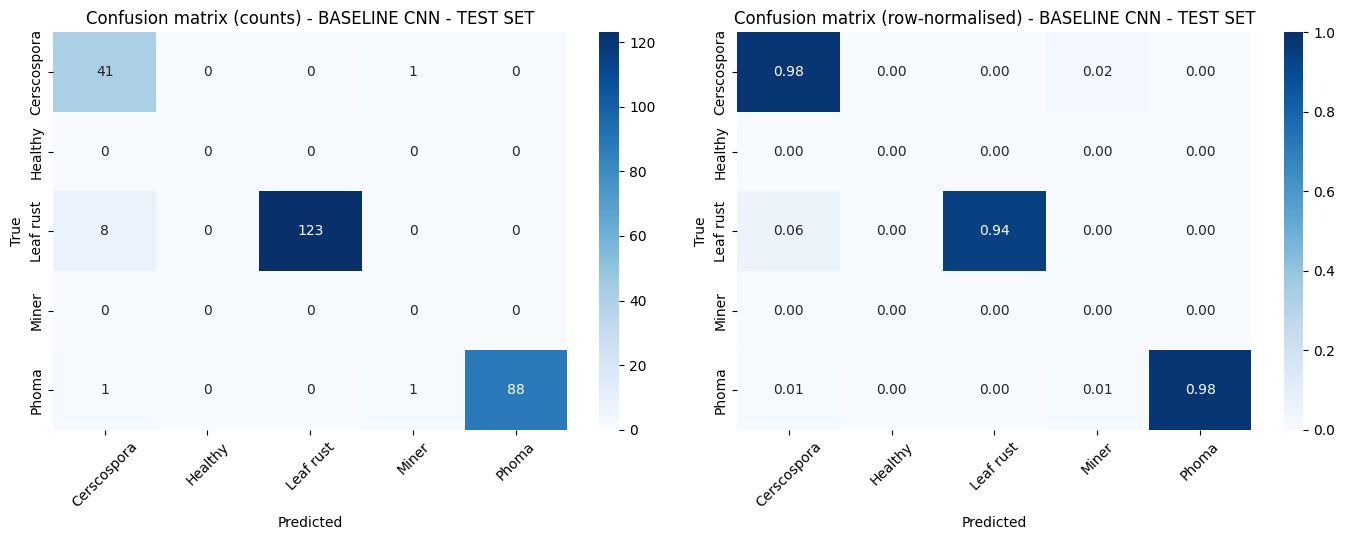

Inference time: 1.60 ms/image


In [21]:
model_registry = {}   # name -> dict(model, params, test_metrics, val_acc, inference_ms, history_dicts)

baseline = None
if RUN_BASELINE:
    baseline = models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        layers.Resizing(128, 128),
        layers.Rescaling(1. / 255),
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="baseline_cnn")
    baseline.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    baseline.summary()
    hb = baseline.fit(train_ds, validation_data=val_ds, epochs=BASELINE_EPOCHS, class_weight=class_weight,
                      callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
    overfitting_check([hb.history], "baseline_cnn")
    res_base = evaluate_frame(baseline, test_df, "BASELINE CNN - TEST SET", "baseline_test")
    val_loss_b, val_acc_b = baseline.evaluate(val_ds, verbose=0)
    inf_ms_b = measure_inference_time(baseline, test_df)
    model_registry["Baseline CNN"] = {"model": baseline, "params": int(baseline.count_params()), "val_acc": float(val_acc_b),
                                      "test_metrics": res_base, "inference_ms": inf_ms_b, "history_dicts": [hb.history]}
    print(f"Inference time: {inf_ms_b:.2f} ms/image")
else:
    print("Baseline skipped (RUN_BASELINE = False).")

## Phase 10–13 — Transfer Learning (multiple architectures, two-stage, class imbalance handled)

**Phase 10 — candidate pretrained architectures.** All five are configured below; `ARCHITECTURES_TO_TRAIN` (Part 1) selects which ones actually train in this run (training all five takes a long time — start small).

**Phase 11 — architecture.** For every backbone: `Input → (architecture's own preprocess_input) → backbone (ImageNet weights, include_top=False) → GlobalAveragePooling2D → Dropout → Dense(softmax, NUM_CLASSES)`.

**Phase 12 — two-stage training**, identical procedure for every architecture:
- **Stage 1 (feature extraction):** backbone frozen, only the new head trains (Adam, lr 1e-3).
- **Stage 2 (fine-tuning):** the last `FINE_TUNE_LAST_N_LAYERS` layers of the backbone are unfrozen and trained with a small learning rate (Adam, 1e-5).

**Phase 13 — class imbalance** is handled with `class_weight` (computed in Part 13, from the train split only) applied in both stages.


MobileNetV2
--- MobileNetV2: Stage 1 (feature extraction, backbone frozen) ---
Epoch 1/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 71s 586ms/step - accuracy: 0.7527 - loss: 0.7711 - val_accuracy: 0.9069 - val_loss: 0.2574 - learning_rate: 0.0010
Epoch 2/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 50s 498ms/step - accuracy: 0.8907 - loss: 0.2665 - val_accuracy: 0.9172 - val_loss: 0.2047 - learning_rate: 0.0010
Epoch 3/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 50s 499ms/step - accuracy: 0.9188 - loss: 0.1971 - val_accuracy: 0.9655 - val_loss: 0.1067 - learning_rate: 0.0010
Epoch 4/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 50s 493ms/step - accuracy: 0.9326 - loss: 0.1596 - val_accuracy: 0.9586 - val_loss: 0.1158 - learning_rate: 0.0010
Epoch 5/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 83s 503ms/step - accuracy: 0.9451 - loss: 0.1387 - val_accuracy: 0.9793 - val_loss: 0.0506 - learning_rate: 0.0010
Epoch 6/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 50s 495ms/step - accuracy: 0.9488 - loss: 0.1210 - val_accuracy: 0.9931 - val_loss: 0.0482 - learning_rate: 0.0

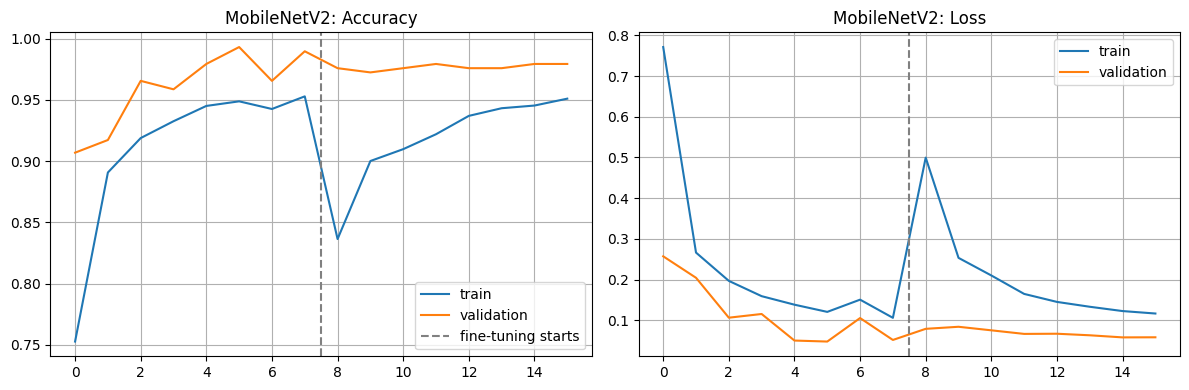

[saved table]  report_evidence/tables/training_history_MobileNetV2.csv
===== MobileNetV2 - TEST SET: 263 images =====
Accuracy: 98.10% | Precision(macro): 0.5953 | Recall(macro): 0.5896 | Macro-F1: 0.5923 | Weighted-F1: 0.9884



,precision,recall,f1-score,support
Cerscospora,0.9767,1.0000,0.9882,42.000
Healthy,0.0000,0.0000,0.0000,0.000
Leaf rust,1.0000,0.9924,0.9962,131.000
Miner,0.0000,0.0000,0.0000,0.000
Phoma,1.0000,0.9556,0.9773,90.000
accuracy,0.9810,0.9810,0.9810,0.981
macro avg,0.5953,0.5896,0.5923,263.000
weighted avg,0.9963,0.9810,0.9884,263.000


[saved table]  report_evidence/tables/classification_report_MobileNetV2_test.csv
[saved figure] report_evidence/figures/confusion_matrix_MobileNetV2_test.png


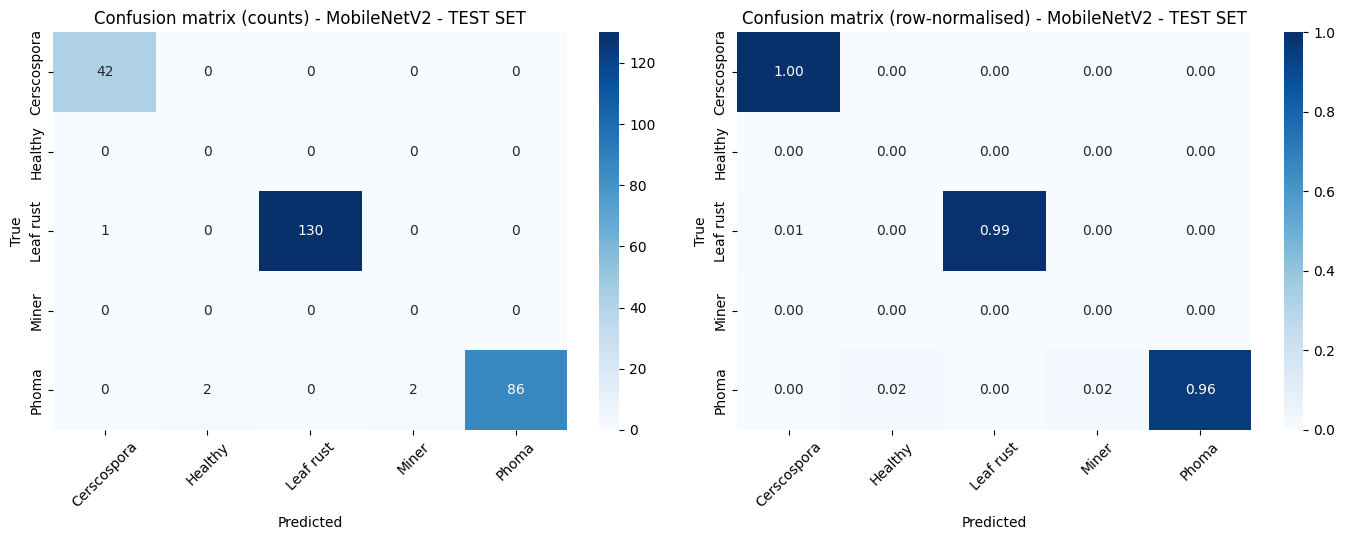

MobileNetV2: val_acc=0.9793 | test_acc=0.9810 | macro_F1=0.5923 | inference=3.11 ms/image

EfficientNetB0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- EfficientNetB0: Stage 1 (feature extraction, backbone frozen) ---
Epoch 1/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 106s 786ms/step - accuracy: 0.7818 - loss: 0.6862 - val_accuracy: 0.8931 - val_loss: 0.3450 - learning_rate: 0.0010
Epoch 2/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 52s 515ms/step - accuracy: 0.9160 - loss: 0.2783 - val_accuracy: 0.9517 - val_loss: 0.1956 - learning_rate: 0.0010
Epoch 3/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 52s 512ms/step - accuracy: 0.9385 - loss: 0.1901 - val_accuracy: 0.9517 - val_loss: 0.1607 - learning_rate: 0.0010
Epoch 4/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 52s 511ms/step - accuracy: 0.9438 - loss: 0.1553 - val_accuracy: 0.9586 - val_loss: 0.1277 - learning_rate: 0.0010
Epoch 5/8
101/101 ━━━━━━━━━━━━━━━━━━━━ 52s 512ms/step - accuracy: 0.9575 - loss: 0.1313 - val_accuracy: 0.9655 - val_loss: 0.1264 - learning_rate: 0.0010
Ep

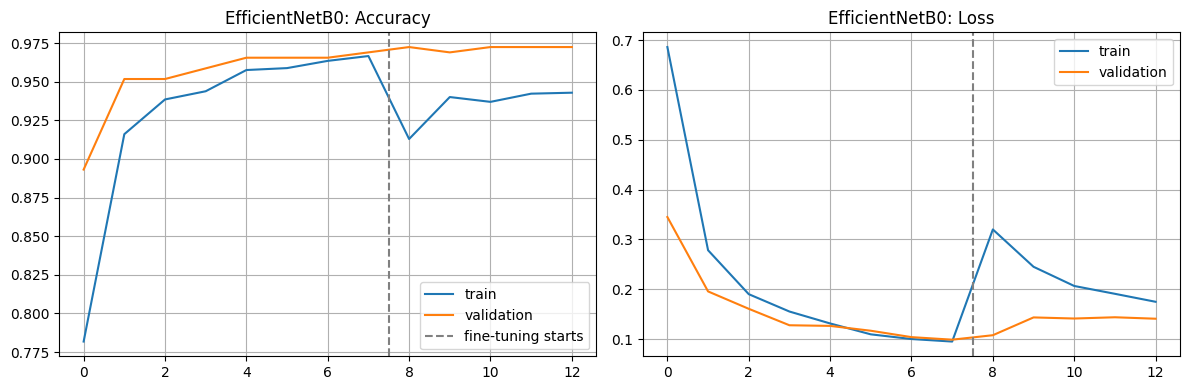

[saved table]  report_evidence/tables/training_history_EfficientNetB0.csv
===== EfficientNetB0 - TEST SET: 263 images =====
Accuracy: 97.34% | Precision(macro): 0.5818 | Recall(macro): 0.5815 | Macro-F1: 0.5815 | Weighted-F1: 0.9792



,precision,recall,f1-score,support
Cerscospora,0.9091,0.9524,0.9302,42.0000
Healthy,0.0000,0.0000,0.0000,0.0000
Leaf rust,1.0000,0.9771,0.9884,131.0000
Miner,0.0000,0.0000,0.0000,0.0000
Phoma,1.0000,0.9778,0.9888,90.0000
accuracy,0.9734,0.9734,0.9734,0.9734
macro avg,0.5818,0.5815,0.5815,263.0000
weighted avg,0.9855,0.9734,0.9792,263.0000


[saved table]  report_evidence/tables/classification_report_EfficientNetB0_test.csv
[saved figure] report_evidence/figures/confusion_matrix_EfficientNetB0_test.png


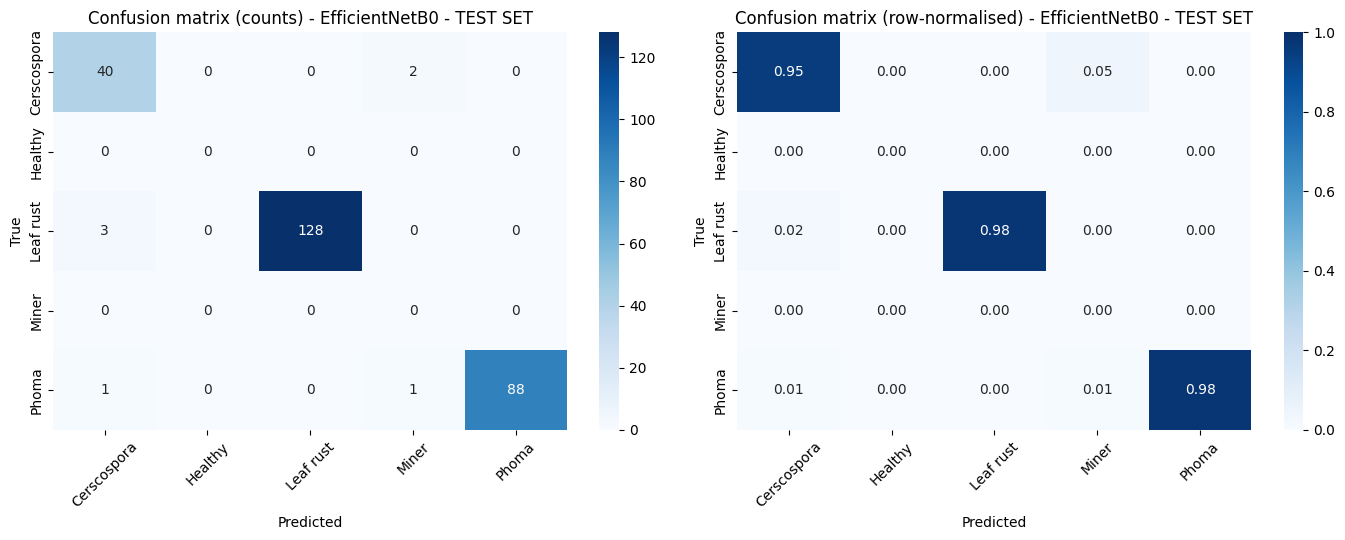

EfficientNetB0: val_acc=0.9724 | test_acc=0.9734 | macro_F1=0.5815 | inference=1.86 ms/image

Trained models: ['Baseline CNN', 'MobileNetV2', 'EfficientNetB0']


In [23]:
ARCH_CONFIGS = {
    "MobileNetV2":   dict(app=tf.keras.applications.MobileNetV2,   preprocess=tf.keras.applications.mobilenet_v2.preprocess_input),
    "EfficientNetB0": dict(app=tf.keras.applications.EfficientNetB0, preprocess=tf.keras.applications.efficientnet.preprocess_input),
    "ResNet50":      dict(app=tf.keras.applications.ResNet50,      preprocess=tf.keras.applications.resnet.preprocess_input),
    "DenseNet121":   dict(app=tf.keras.applications.DenseNet121,   preprocess=tf.keras.applications.densenet.preprocess_input),
    "Xception":      dict(app=tf.keras.applications.Xception,      preprocess=tf.keras.applications.xception.preprocess_input),
}

def build_transfer_model(arch_name):
    cfg = ARCH_CONFIGS[arch_name]
    base = cfg["app"](input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = layers.Input(shape=IMG_SIZE + (3,), name="image")                 # raw 0-255 pixels
    x = layers.Lambda(cfg["preprocess"], name="preprocess")(inputs)            # architecture-specific normalization
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="probs")(x)
    return models.Model(inputs, outputs, name=arch_name), base

def train_one_architecture(arch_name):
    print("\n" + "=" * 70 + f"\n{arch_name}\n" + "=" * 70)
    model, base = build_transfer_model(arch_name)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    print(f"--- {arch_name}: Stage 1 (feature extraction, backbone frozen) ---")
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=PHASE1_EPOCHS, class_weight=class_weight,
                   callbacks=make_callbacks(f"best_{arch_name}_stage1.keras"))

    print(f"--- {arch_name}: Stage 2 (fine-tuning last {FINE_TUNE_LAST_N_LAYERS} layers) ---")
    base.trainable = True
    for layer in base.layers[:-FINE_TUNE_LAST_N_LAYERS]:
        layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=PHASE2_EPOCHS, class_weight=class_weight,
                   callbacks=make_callbacks(f"best_{arch_name}_stage2.keras"))

    overfitting_check([h1.history, h2.history], arch_name)

    acc = h1.history["accuracy"] + h2.history["accuracy"]; val_acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
    loss = h1.history["loss"] + h2.history["loss"]; val_loss = h1.history["val_loss"] + h2.history["val_loss"]
    switch = len(h1.history["accuracy"]) - 0.5
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="validation"); ax[0].axvline(switch, color="gray", ls="--", label="fine-tuning starts")
    ax[0].set_title(f"{arch_name}: Accuracy"); ax[0].legend(); ax[0].grid(True)
    ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="validation"); ax[1].axvline(switch, color="gray", ls="--")
    ax[1].set_title(f"{arch_name}: Loss"); ax[1].legend(); ax[1].grid(True)
    plt.tight_layout(); save_fig(f"learning_curves_{arch_name}"); plt.show()

    hist_df = pd.DataFrame({"accuracy": acc, "val_accuracy": val_acc, "loss": loss, "val_loss": val_loss}); hist_df.index.name = "epoch"
    save_table(hist_df.round(5), f"training_history_{arch_name}")

    res_test = evaluate_frame(model, test_df, f"{arch_name} - TEST SET", f"{arch_name}_test")
    val_loss_f, val_acc_f = model.evaluate(val_ds, verbose=0)
    inf_ms = measure_inference_time(model, test_df)
    model_registry[arch_name] = {"model": model, "params": int(model.count_params()), "val_acc": float(val_acc_f),
                                 "test_metrics": res_test, "inference_ms": inf_ms, "history_dicts": [h1.history, h2.history]}
    print(f"{arch_name}: val_acc={val_acc_f:.4f} | test_acc={res_test['acc']:.4f} | macro_F1={res_test['macro_f1']:.4f} | inference={inf_ms:.2f} ms/image")
    return model

for arch_name in ARCHITECTURES_TO_TRAIN:
    if arch_name not in ARCH_CONFIGS:
        print(f"Skipping unknown architecture '{arch_name}' (not in ARCH_CONFIGS)."); continue
    train_one_architecture(arch_name)

print("\nTrained models:", list(model_registry.keys()))

## Phase 17–18 — Metrics and Confusion Matrix (already produced above)
Accuracy, precision, recall, F1, macro-F1 and weighted-F1 were printed and saved for every model as it was evaluated (Parts 14–15), together with its confusion matrix. The comparison table in Phase 22 collects them side by side.

## Phase 19 — ROC and Precision-Recall Analysis (one-vs-rest, multi-class)
Computed for every trained model on the **test set**: per-class ROC curve + AUC, per-class Precision-Recall curve + average precision, and the macro-averaged ROC-AUC.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarnin

[saved figure] report_evidence/figures/roc_pr_Baseline CNN.png


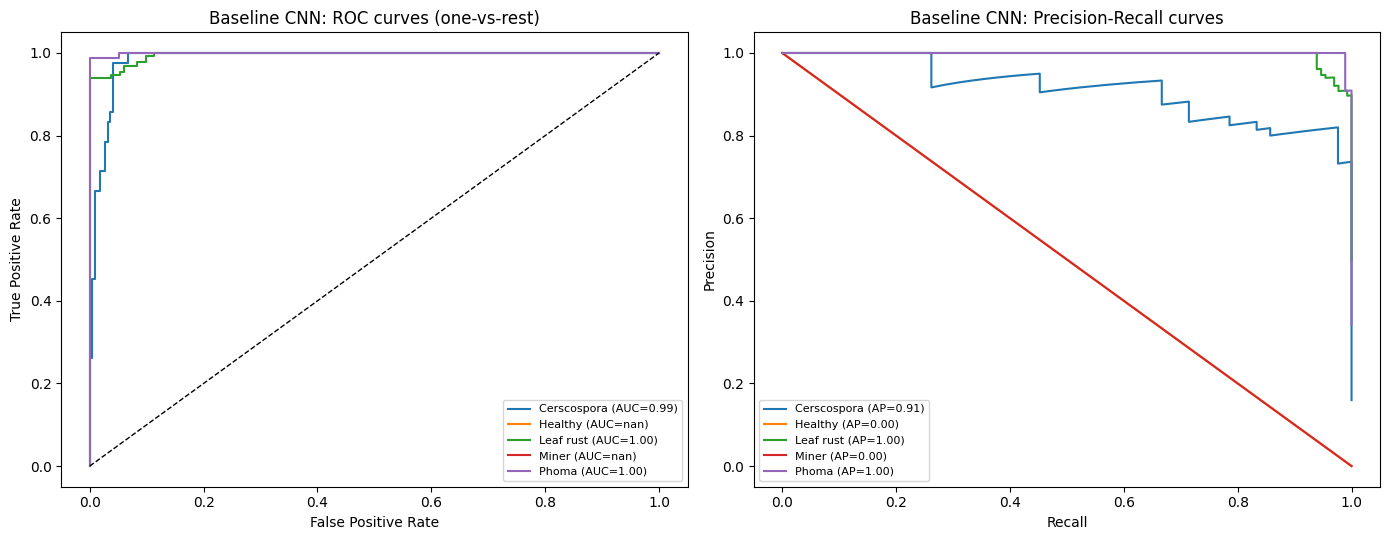

Baseline CNN: macro ROC-AUC = nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


,ROC_AUC,Average_Precision
Cerscospora,0.9856,0.9136
Healthy,NaN,0.0000
Leaf rust,0.9954,0.9956
Miner,NaN,0.0000
Phoma,0.9994,0.9990


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarnin

[saved table]  report_evidence/tables/roc_pr_table_Baseline CNN.csv
[saved figure] report_evidence/figures/roc_pr_MobileNetV2.png


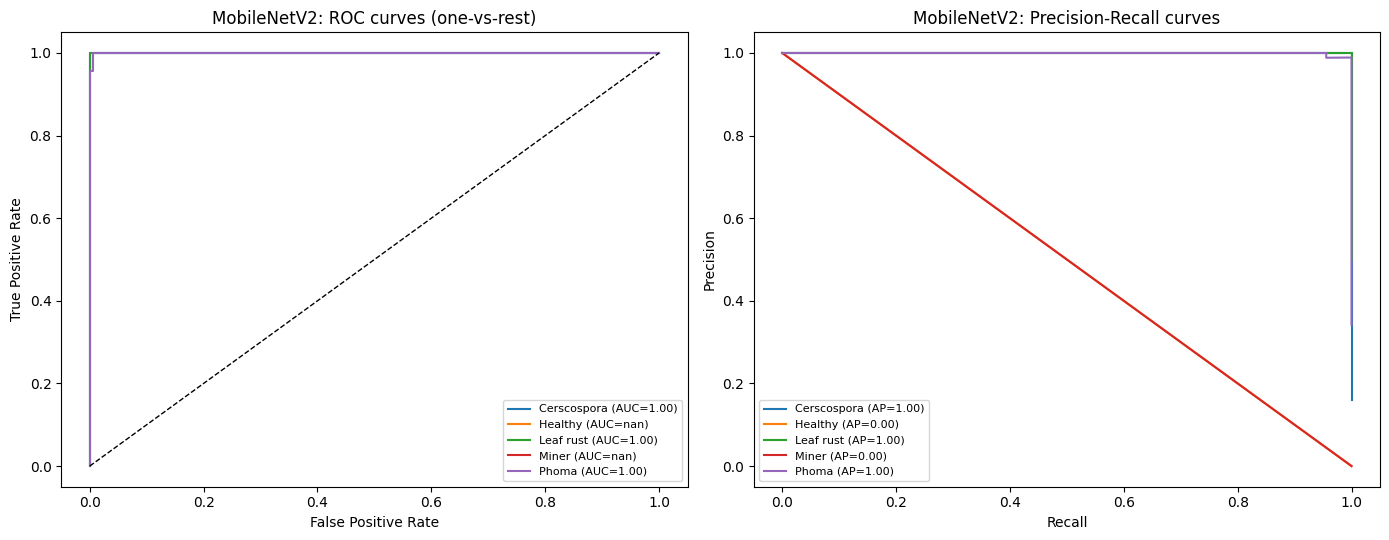

MobileNetV2: macro ROC-AUC = nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


,ROC_AUC,Average_Precision
Cerscospora,1.0000,1.0000
Healthy,NaN,0.0000
Leaf rust,1.0000,1.0000
Miner,NaN,0.0000
Phoma,0.9997,0.9995


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarnin

[saved table]  report_evidence/tables/roc_pr_table_MobileNetV2.csv
[saved figure] report_evidence/figures/roc_pr_EfficientNetB0.png


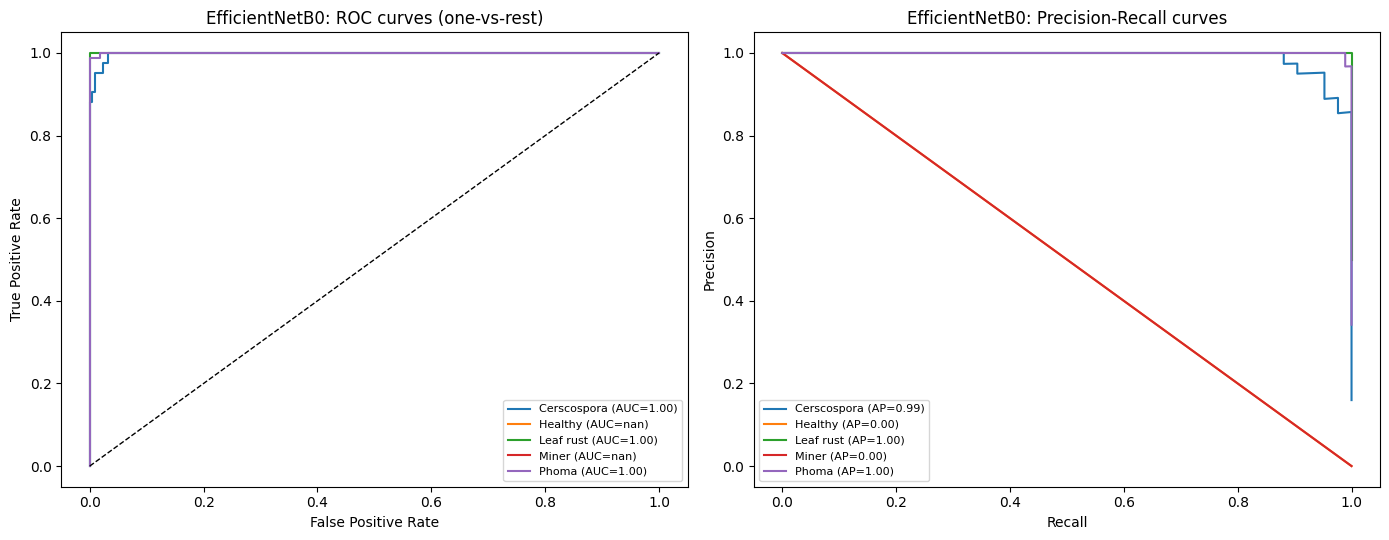

EfficientNetB0: macro ROC-AUC = nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


,ROC_AUC,Average_Precision
Cerscospora,0.9982,0.9911
Healthy,NaN,0.0000
Leaf rust,1.0000,1.0000
Miner,NaN,0.0000
Phoma,0.9998,0.9996


[saved table]  report_evidence/tables/roc_pr_table_EfficientNetB0.csv


In [24]:
def plot_roc_pr(name, res):
    y_true_bin = label_binarize(res["y_true"], classes=list(range(NUM_CLASSES)))
    probs = res["probs"]
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
    aucs, aps = {}, {}
    for i, c in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], probs[:, i]); roc_auc = auc(fpr, tpr); aucs[c] = float(roc_auc)
        ax[0].plot(fpr, tpr, label=f"{c} (AUC={roc_auc:.2f})")
        prec, rec, _ = precision_recall_curve(y_true_bin[:, i], probs[:, i]); ap = average_precision_score(y_true_bin[:, i], probs[:, i]); aps[c] = float(ap)
        ax[1].plot(rec, prec, label=f"{c} (AP={ap:.2f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate")
    ax[0].set_title(f"{name}: ROC curves (one-vs-rest)"); ax[0].legend(fontsize=8)
    ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title(f"{name}: Precision-Recall curves"); ax[1].legend(fontsize=8)
    plt.tight_layout(); save_fig(f"roc_pr_{name}"); plt.show()
    macro_auc = float(roc_auc_score(y_true_bin, probs, average="macro", multi_class="ovr"))
    print(f"{name}: macro ROC-AUC = {macro_auc:.4f}")
    tbl = pd.DataFrame({"ROC_AUC": aucs, "Average_Precision": aps})
    display(tbl.round(4)); save_table(tbl.round(4), f"roc_pr_table_{name}")
    return {"macro_roc_auc": macro_auc, "per_class": tbl.to_dict()}

roc_pr_results = {}
for name, info in model_registry.items():
    roc_pr_results[name] = plot_roc_pr(name, info["test_metrics"])
RESULTS["roc_pr"] = roc_pr_results

## Phase 20 — Error Analysis

Builds a table of every **misclassified test image** for the best-performing model so far (by test macro-F1): actual class, predicted class, confidence, and the image itself. `likely_reason` is left blank for you to fill in after looking at each image — use the checklist in the markdown below it.

Possible reasons to consider while filling it in: similar disease symptoms between classes, poor image quality, lighting, leaf orientation, background clutter, multiple symptoms on one leaf, early-stage disease (subtle symptoms), or an incorrect original label.

Error analysis for: MobileNetV2 (highest test macro-F1 so far: 0.5923)

Misclassified: 5 of 263 test images (1.9%)


,path,actual_class,predicted_class,confidence,likely_reason
0,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Pho...,Phoma,Miner,0.9655,
1,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Pho...,Phoma,Healthy,0.9257,
2,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Pho...,Phoma,Healthy,0.8555,
3,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Pho...,Phoma,Miner,0.7878,
4,/kaggle/input/jmuben-coffee-dataset/JMuBEN/Lea...,Leaf rust,Cerscospora,0.5248,


[saved table]  report_evidence/tables/phase20_error_analysis_table.csv
[saved figure] report_evidence/figures/phase20_top_errors.png


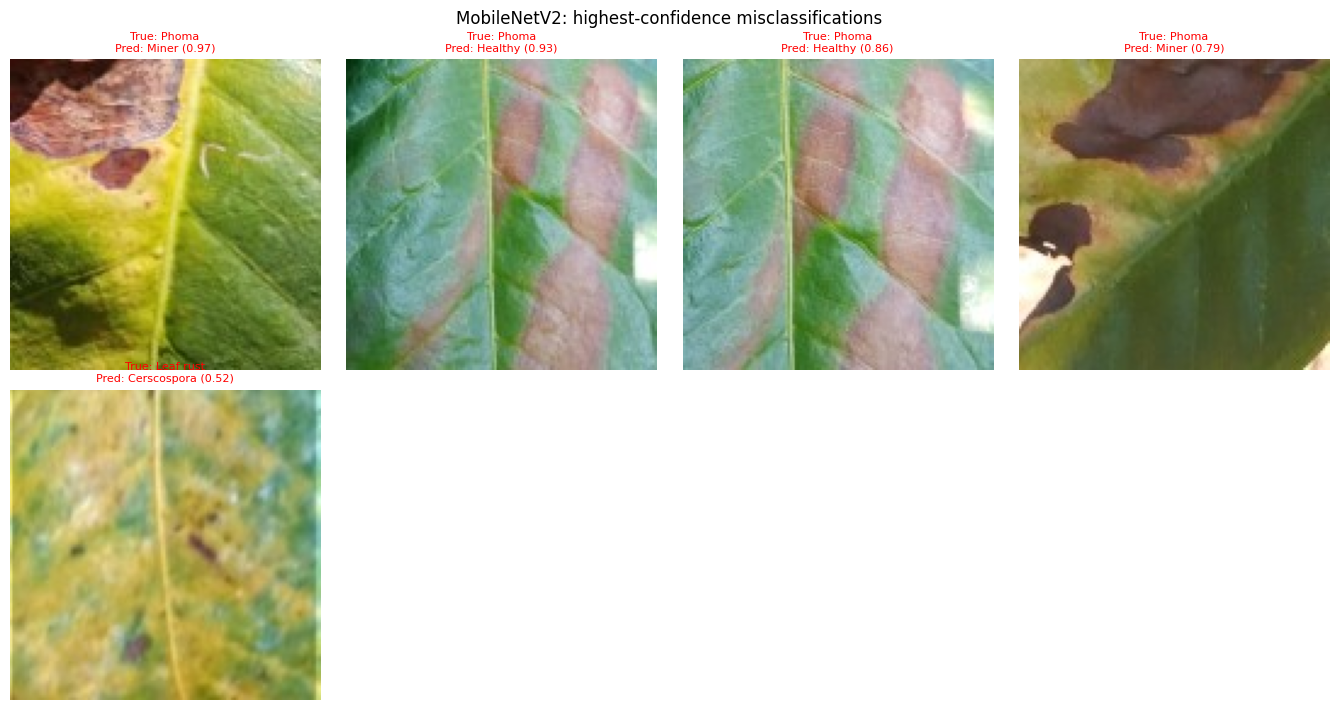


Most confused class pairs:


,actual,predicted_as,count
1,Phoma,Healthy,2
2,Phoma,Miner,2
0,Leaf rust,Cerscospora,1


[saved table]  report_evidence/tables/phase20_confused_pairs.csv


In [25]:
_best_name_so_far = max(model_registry, key=lambda n: model_registry[n]["test_metrics"]["macro_f1"])
_res = model_registry[_best_name_so_far]["test_metrics"]
print(f"Error analysis for: {_best_name_so_far} (highest test macro-F1 so far: {_res['macro_f1']:.4f})")

wrong_idx = np.where(_res["y_pred"] != _res["y_true"])[0]
conf = _res["probs"].max(1)
error_table = pd.DataFrame({
    "path": test_df["path"].values[wrong_idx],
    "actual_class": [class_names[i] for i in _res["y_true"][wrong_idx]],
    "predicted_class": [class_names[i] for i in _res["y_pred"][wrong_idx]],
    "confidence": conf[wrong_idx].round(4),
    "likely_reason": "",   # fill in manually after reviewing the images below
}).sort_values("confidence", ascending=False).reset_index(drop=True)
print(f"\nMisclassified: {len(error_table)} of {len(test_df)} test images ({len(error_table)/len(test_df)*100:.1f}%)")
display(error_table.head(20))
save_table(error_table, "phase20_error_analysis_table", index=False)

# Show the highest-confidence WRONG predictions first (most concerning / most informative)
show = error_table.head(12)
cols = 4; rws = int(np.ceil(len(show) / cols))
fig, axes = plt.subplots(rws, cols, figsize=(3.4 * cols, 3.6 * rws)); axes = np.atleast_1d(axes).ravel()
for ax in axes: ax.axis("off")
for ax, (_, row) in zip(axes, show.iterrows()):
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.set_title(f"True: {row['actual_class']}\nPred: {row['predicted_class']} ({row['confidence']:.2f})", fontsize=8, color="red")
plt.suptitle(f"{_best_name_so_far}: highest-confidence misclassifications")
plt.tight_layout(); save_fig("phase20_top_errors"); plt.show()

# Which class pairs get confused most often (from the confusion matrix)
cm = confusion_matrix(_res["y_true"], _res["y_pred"], labels=list(range(NUM_CLASSES)))
np.fill_diagonal(cm, 0)
pairs = [(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm[i, j] > 0]
pairs_df = pd.DataFrame(pairs, columns=["actual", "predicted_as", "count"]).sort_values("count", ascending=False)
print("\nMost confused class pairs:"); display(pairs_df.head(10)); save_table(pairs_df, "phase20_confused_pairs", index=False)
RESULTS["error_analysis"] = {"model": _best_name_so_far, "misclassified": int(len(error_table)), "total_test": int(len(test_df))}

**Checklist to use while filling in `likely_reason` in `report_evidence/tables/phase20_error_analysis_table.csv`:** similar disease symptoms · poor image quality · lighting · leaf orientation · background · multiple symptoms · early-stage disease · incorrect label. Summarize the patterns you find (e.g. "most errors are between X and Y, which look similar in early stages") in the report's Discussion and Limitations sections.

## Phase 22 — Compare Models

,Model,Accuracy,Precision(macro),Recall(macro),F1(macro),F1(weighted),ROC_AUC(macro),Parameters,Inference_ms_per_image
0,MobileNetV2,0.9810,0.5953,0.5896,0.5923,0.9884,NaN,2264389,3.11
1,EfficientNetB0,0.9734,0.5818,0.5815,0.5815,0.9792,NaN,4055976,1.86
2,Baseline CNN,0.9582,0.5640,0.5786,0.5697,0.9631,NaN,3305285,1.60


[saved table]  report_evidence/tables/phase22_model_comparison.csv
[saved figure] report_evidence/figures/phase22_model_comparison_charts.png


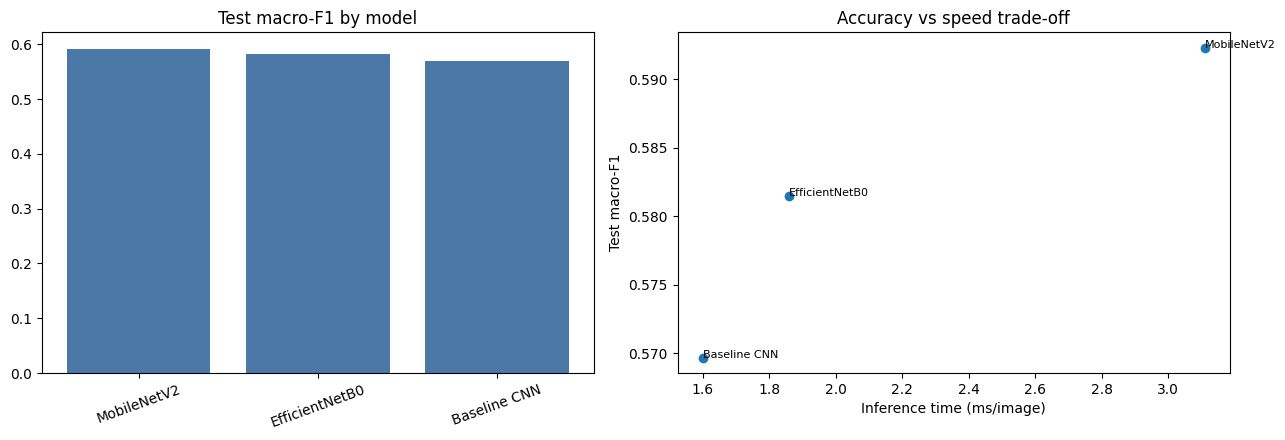

In [26]:
rows_cmp = []
for name, info in model_registry.items():
    tm = info["test_metrics"]
    rows_cmp.append({"Model": name, "Accuracy": round(tm["acc"], 4), "Precision(macro)": round(tm["precision_macro"], 4),
                     "Recall(macro)": round(tm["recall_macro"], 4), "F1(macro)": round(tm["macro_f1"], 4),
                     "F1(weighted)": round(tm["weighted_f1"], 4), "ROC_AUC(macro)": round(roc_pr_results[name]["macro_roc_auc"], 4),
                     "Parameters": info["params"], "Inference_ms_per_image": round(info["inference_ms"], 2)})
comparison_df = pd.DataFrame(rows_cmp).sort_values("F1(macro)", ascending=False).reset_index(drop=True)
display(comparison_df); save_table(comparison_df, "phase22_model_comparison", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(comparison_df["Model"], comparison_df["F1(macro)"], color="#4c78a8"); ax[0].set_title("Test macro-F1 by model"); ax[0].tick_params(axis="x", rotation=20)
ax[1].scatter(comparison_df["Inference_ms_per_image"], comparison_df["F1(macro)"])
for _, r in comparison_df.iterrows(): ax[1].annotate(r["Model"], (r["Inference_ms_per_image"], r["F1(macro)"]), fontsize=8)
ax[1].set_xlabel("Inference time (ms/image)"); ax[1].set_ylabel("Test macro-F1"); ax[1].set_title("Accuracy vs speed trade-off")
plt.tight_layout(); save_fig("phase22_model_comparison_charts"); plt.show()
RESULTS["model_comparison"] = comparison_df.to_dict(orient="records")

## Phase 23 — Final Model Selection

Picks the model with the highest test **macro-F1** (fairest single number under class imbalance), and prints a short comparison against model size and inference speed so the choice can be justified against the actual requirement (a mobile app) rather than by an arbitrary score alone. Override `FORCE_FINAL_MODEL` below if you want to select a different model for a documented reason (e.g. a much smaller model that is "good enough").

In [27]:
FORCE_FINAL_MODEL = None   # e.g. "MobileNetV2" — leave as None to auto-select by macro-F1

final_name = FORCE_FINAL_MODEL or comparison_df.iloc[0]["Model"]
final_info = model_registry[final_name]
final_model = final_info["model"]

print("=" * 60); print("FINAL MODEL SELECTION"); print("=" * 60)
print(f"Selected model     : {final_name}")
print(f"Test accuracy       : {final_info['test_metrics']['acc']*100:.2f}%")
print(f"Test macro-F1       : {final_info['test_metrics']['macro_f1']:.4f}")
print(f"Test ROC-AUC (macro): {roc_pr_results[final_name]['macro_roc_auc']:.4f}")
print(f"Parameters          : {final_info['params']:,}")
print(f"Inference time      : {final_info['inference_ms']:.2f} ms/image")
print("\nReasoning for the report: highest test macro-F1 among the trained architectures balances per-class")
print("performance under class imbalance; parameter count and inference time (above) support that it is also")
print("small/fast enough to consider for the mobile app (compare against the other rows in the Phase 22 table).")
smaller_but_close = comparison_df[(comparison_df["Model"] != final_name) &
                                  (comparison_df["F1(macro)"] >= comparison_df["F1(macro)"].max() - 0.01) &
                                  (comparison_df["Parameters"] < final_info["params"])]
if len(smaller_but_close):
    print("\nNOTE: the following models are within 0.01 macro-F1 of the best score but smaller — consider them")
    print("      if app size/speed matters more than the last fraction of accuracy:")
    display(smaller_but_close)
RESULTS["final_selection"] = {"model": final_name, "test_acc": final_info["test_metrics"]["acc"],
                              "test_macro_f1": final_info["test_metrics"]["macro_f1"], "params": final_info["params"],
                              "inference_ms": final_info["inference_ms"]}

FINAL MODEL SELECTION
Selected model     : MobileNetV2
Test accuracy       : 98.10%
Test macro-F1       : 0.5923
Test ROC-AUC (macro): nan
Parameters          : 2,264,389
Inference time      : 3.11 ms/image

Reasoning for the report: highest test macro-F1 among the trained architectures balances per-class
performance under class imbalance; parameter count and inference time (above) support that it is also
small/fast enough to consider for the mobile app (compare against the other rows in the Phase 22 table).


## Phase 24 — Save the Final Model and Metadata

Saves everything needed to reproduce inference exactly, in the structure the guideline asks for:
```
models/
└── coffee_disease_model/
    ├── model.keras                 (or a SavedModel folder)
    ├── class_names.json
    ├── preprocessing_config.json
    └── model_metadata.json
```

In [28]:
MODEL_DIR = "models/coffee_disease_model"
os.makedirs(MODEL_DIR, exist_ok=True)

final_model.save(f"{MODEL_DIR}/model.keras")

with open(f"{MODEL_DIR}/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

preprocessing_config = {
    "input_size": list(IMG_SIZE), "channels": 3,
    "input_dtype": "float32", "input_range": "raw pixel values 0-255 (normalization happens INSIDE the model)",
    "architecture": final_name, "keras_preprocess_function": f"tf.keras.applications.{final_name.lower()}.preprocess_input (baked into the model as a Lambda layer)",
    "resize_method": "tf.image.resize to 224x224 (bilinear, no crop, no padding)",
}
with open(f"{MODEL_DIR}/preprocessing_config.json", "w") as f: json.dump(preprocessing_config, f, indent=2)

model_metadata = {
    "project": "Coffee Leaf Disease Detection - Internship Project (DBU, Dept. of Data Science)",
    "date_trained": time.strftime("%Y-%m-%d"),
    "architecture": final_name, "parameters": final_info["params"],
    "dataset": {"source": "JMuBEN coffee leaf dataset (Kaggle)", "raw_files": int(len(df)),
               "used_after_cleaning": int(len(data)), "classes": class_names,
               "split": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}},
    "test_metrics": {k: v for k, v in final_info["test_metrics"].items() if k in ("acc", "precision_macro", "recall_macro", "macro_f1", "weighted_f1")},
    "roc_auc_macro": roc_pr_results[final_name]["macro_roc_auc"],
    "inference_ms_per_image": final_info["inference_ms"],
    "suggested_confidence_threshold": CONF_THRESHOLD,
}
def _default(o):
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    return str(o)
with open(f"{MODEL_DIR}/model_metadata.json", "w") as f: json.dump(model_metadata, f, indent=2, default=_default)

print("Saved:"); [print(" -", os.path.join(MODEL_DIR, fn)) for fn in os.listdir(MODEL_DIR)]
RESULTS["saved_model_dir"] = MODEL_DIR

Saved:
 - models/coffee_disease_model/class_names.json
 - models/coffee_disease_model/model_metadata.json
 - models/coffee_disease_model/preprocessing_config.json
 - models/coffee_disease_model/model.keras


## Real phone photos (strongly recommended)
The most important check for a farmer-facing app: dataset photos may not look like real farm photos. Set `RUN_REAL_PHOTO_TEST = True` in Part 1, run this cell, and upload `real_photos.zip` with one sub-folder per class (folder names must match `class_names` exactly), at least ~10 photos per class.

In [29]:
if RUN_REAL_PHOTO_TEST:
    from google.colab import files
    print("Classes expected as folder names:", class_names)
    uploaded = files.upload()
    if uploaded:
        zname = list(uploaded.keys())[0]
        shutil.rmtree("real_test", ignore_errors=True)
        with zipfile.ZipFile(zname) as zf: zf.extractall("real_test")
        root = "real_test"
        subs = [d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))]
        if len(subs) == 1 and subs[0] not in class_names: root = os.path.join(root, subs[0])
        rrows = []
        for c in os.listdir(root):
            cdir = os.path.join(root, c)
            if not os.path.isdir(cdir) or c not in class_names: continue
            for f in os.listdir(cdir):
                if f.lower().endswith(IMG_EXT): rrows.append((os.path.join(cdir, f), c, label_of[c]))
        real_df = pd.DataFrame(rrows, columns=["path", "class", "label"])
        if len(real_df):
            res_real = evaluate_frame(final_model, real_df, f"{final_name} - REAL PHONE PHOTOS", "real_photos")
            RESULTS["real_photos"] = {"images": len(real_df), "acc": res_real["acc"], "macro_f1": res_real["macro_f1"]}
        else:
            print("No usable images found.")
else:
    print("Skipped (RUN_REAL_PHOTO_TEST = False). Strongly recommended before claiming the app works for farmers.")

Skipped (RUN_REAL_PHOTO_TEST = False). Strongly recommended before claiming the app works for farmers.


## TFLite Export (final selected model, for the Flutter app)

In [30]:
converter = tf.lite.TFLiteConverter.from_keras_model(final_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

os.makedirs("export", exist_ok=True)
with open("export/coffee_leaf_model.tflite", "wb") as f: f.write(tflite_model)
shutil.copy(f"{MODEL_DIR}/class_names.json", "export/labels.json")
with open("export/labels.txt", "w") as f:
    for name in class_names: f.write(name + "\n")
info = {"input_size": list(IMG_SIZE), "channels": 3, "architecture": final_name,
        "input_type": "float32, RAW pixel values 0-255 (do NOT divide by 255 in the app)",
        "resize": "direct resize to 224x224 (no crop, no padding)", "classes": class_names,
        "suggested_confidence_threshold": CONF_THRESHOLD}
with open("export/model_info.json", "w") as f: json.dump(info, f, indent=2)
tflite_mb = len(tflite_model) / 1024 / 1024
print(f"TFLite size: {tflite_mb:.2f} MB")

interp = tf.lite.Interpreter(model_content=tflite_model); interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
sample = test_df.sample(min(200, len(test_df)), random_state=1)
xs, tflite_preds = [], []
for p, l in zip(sample["path"], sample["label"]):
    im_, _ = load_image(p, l); xx = im_.numpy()[None].astype("float32"); xs.append(xx)
    interp.set_tensor(inp["index"], xx); interp.invoke(); tflite_preds.append(int(interp.get_tensor(out["index"]).argmax()))
keras_preds = final_model.predict(np.concatenate(xs), verbose=0).argmax(1); tflite_preds = np.array(tflite_preds); yt = sample["label"].values
RESULTS["tflite"] = {"size_mb": round(tflite_mb, 3), "sample_size": len(sample),
                     "keras_acc_sample": float((keras_preds == yt).mean()), "tflite_acc_sample": float((tflite_preds == yt).mean()),
                     "keras_tflite_agreement": float((keras_preds == tflite_preds).mean())}
print(f"Keras vs TFLite agreement: {RESULTS['tflite']['keras_tflite_agreement']*100:.1f}%")

print("\nNotes for the app: input 224x224 RGB float32 raw 0-255 (resize only, no /255); labels.txt line order = output index;")
print(f"if top probability < {CONF_THRESHOLD}, show 'Not sure, please retake the photo' instead of a diagnosis;")
print("add a disclaimer: results are an estimate, not an expert diagnosis.")

Saved artifact at '/tmp/tmp4k6xzcwj'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133427781610448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858318224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858318032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427781908432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858315152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858317648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858319184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858318992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858319376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858318416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133427858318608: Tens

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Keras vs TFLite agreement: 100.0%

Notes for the app: input 224x224 RGB float32 raw 0-255 (resize only, no /255); labels.txt line order = output index;
if top probability < 0.7, show 'Not sure, please retake the photo' instead of a diagnosis;
add a disclaimer: results are an estimate, not an expert diagnosis.


## Evidence Pack

In [31]:
def _default(o):
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
with open(f"{EVIDENCE_DIR}/results_summary.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=_default)

shutil.make_archive("report_evidence", "zip", EVIDENCE_DIR)
shutil.make_archive("coffee_app_model", "zip", "export")
shutil.make_archive("saved_model", "zip", "models")
print("Created: report_evidence.zip, coffee_app_model.zip, saved_model.zip")

if DOWNLOAD_AT_END:
    try:
        from google.colab import files
        for z in ["report_evidence.zip", "coffee_app_model.zip", "saved_model.zip"]:
            files.download(z)
    except Exception as e:
        print("Auto-download not available here:", e)

Created: report_evidence.zip, coffee_app_model.zip, saved_model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>